# 🔬 MGD Seed Models Comprehensive Comparison

<div align="center">

**Systematic Analysis of Different Seed Models in Minimal Geometrical Deformation Theory**

*TolmanIV vs HeintzmannIIa vs WymanIIa: Performance, Stability, and Physical Properties*

---

</div>

## 🎯 **Comparative Analysis Overview**

This notebook provides a comprehensive comparison of the three seed models implemented in the MGD stars package:

| **Model** | **Metric Structure** | **Key Features** | **Applications** |
|-----------|---------------------|------------------|------------------|
| **🌟 TolmanIV** | `e^ν = B₀²(r²/A₀² + 1)` | Standard baseline | Canonical neutron stars |
| **⚡ HeintzmannIIa** | `e^ν = A₀²(B₀r² + 1)³` | Polynomial structure | Alternative parameterization |
| **🔥 WymanIIa** | `e^ν = (A₀ - B₀r²)²` | Quadratic form | Different metric approach |

## 🔍 **Analysis Objectives**

### **1. Numerical Stability Comparison**
- Convergence behavior across different parameter ranges
- Solver robustness for each model
- Precision and accuracy assessment

### **2. Physical Property Analysis**
- Stellar profile differences (density, pressure, anisotropy)
- Parameter sensitivity studies
- Realistic neutron star configurations

### **3. Performance Evaluation**
- Computational efficiency
- Success rates for challenging parameters
- Boundary condition satisfaction

### **4. Scientific Insights**
- Model-dependent physical predictions
- Range of validity for each approach
- Recommendations for specific applications

---

**Ready to explore the differences between MGD seed models!** 🚀

In [25]:
from mgdstars import MGDStars
import matplotlib.pyplot as plt
import numpy as np

In [26]:
# Comprehensive Seed Models Testing Framework
print("="*70)
print("INITIALIZING SEED MODELS COMPARISON FRAMEWORK")
print("="*70)

# Define the seed models to compare
seed_models = {
    'TolmanIV': {
        'name': 'TolmanIV', 
        'description': 'Standard baseline model',
        'metric': 'e^ν = B₀²(r²/A₀² + 1)',
        'color': 'blue'
    },
    'HeintzmannIIa': {
        'name': 'HeintzmannIIa', 
        'description': 'Polynomial structure model',
        'metric': 'e^ν = A₀²(B₀r² + 1)³',
        'color': 'red'
    },
    'WymanIIa': {
        'name': 'WymanIIa', 
        'description': 'Quadratic form model',
        'metric': 'e^ν = (A₀ - B₀r²)²',
        'color': 'green'
    }
}

# Test configuration for realistic neutron star parameters
test_configurations = [
    {"M": 1.4, "R": 12.0, "alpha": 0.1, "name": "Canonical NS", "compactness": 1.4/12.0},
    {"M": 1.0, "R": 10.0, "alpha": 0.08, "name": "Low mass NS", "compactness": 1.0/10.0},
    {"M": 2.0, "R": 11.0, "alpha": 0.15, "name": "High mass NS", "compactness": 2.0/11.0},
    {"M": 1.6, "R": 13.0, "alpha": 0.12, "name": "Medium NS", "compactness": 1.6/13.0},
]

print("Seed Models to Compare:")
for model_key, model_info in seed_models.items():
    print(f"  🔹 {model_info['name']}: {model_info['description']}")
    print(f"     Metric: {model_info['metric']}")

print(f"\nTest Configurations: {len(test_configurations)} neutron star cases")
print("Compactness range:", f"{min([c['compactness'] for c in test_configurations]):.3f}", 
      "to", f"{max([c['compactness'] for c in test_configurations]):.3f}")

# Initialize results storage
comparison_results = {}
for model_name in seed_models.keys():
    comparison_results[model_name] = {
        'successful_cases': [],
        'failed_cases': [],
        'convergence_data': [],
        'physical_data': [],
        'performance_metrics': {}
    }

print("\n✅ Framework initialized successfully!")
print("📊 Ready to perform systematic comparison across all seed models.")

INITIALIZING SEED MODELS COMPARISON FRAMEWORK
Seed Models to Compare:
  🔹 TolmanIV: Standard baseline model
     Metric: e^ν = B₀²(r²/A₀² + 1)
  🔹 HeintzmannIIa: Polynomial structure model
     Metric: e^ν = A₀²(B₀r² + 1)³
  🔹 WymanIIa: Quadratic form model
     Metric: e^ν = (A₀ - B₀r²)²

Test Configurations: 4 neutron star cases
Compactness range: 0.100 to 0.182

✅ Framework initialized successfully!
📊 Ready to perform systematic comparison across all seed models.


In [27]:
# Systematic Comparison Across All Seed Models
print("="*80)
print("COMPREHENSIVE SEED MODELS PERFORMANCE ANALYSIS")
print("="*80)

import time
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Performance tracking
model_performance = {}

for model_name, model_info in seed_models.items():
    print(f"\n{'='*60}")
    print(f"TESTING {model_info['name'].upper()} MODEL")
    print(f"{'='*60}")
    print(f"Description: {model_info['description']}")
    print(f"Metric form: {model_info['metric']}")
    
    model_performance[model_name] = {
        'total_cases': 0,
        'successful_cases': 0,
        'failed_cases': 0,
        'total_time': 0,
        'avg_residual': [],
        'avg_attempts': [],
        'convergence_details': []
    }
    
    for i, config in enumerate(test_configurations):
        print(f"\n  Test {i+1}: {config['name']} (M={config['M']}, R={config['R']}, α={config['alpha']})")
        print(f"  Compactness M/R = {config['compactness']:.3f}")
        print(f"  {'-'*50}")
        
        try:
            # Create solver with specific seed model
            start_time = time.time()
            star = MGDStars(alpha=config['alpha'], seed_model=model_name)
            
            # Attempt to solve
            result = star.solve_star_configuration(
                M_val=config['M'], 
                R_val=config['R'], 
                tolerance=1e-10,
                max_attempts=10,
                verbose=False
            )
            
            solve_time = time.time() - start_time
            model_performance[model_name]['total_time'] += solve_time
            model_performance[model_name]['total_cases'] += 1
            
            if result['converged']:
                model_performance[model_name]['successful_cases'] += 1
                model_performance[model_name]['avg_residual'].append(result['residual_norm'])
                model_performance[model_name]['avg_attempts'].append(result['attempts_made'])
                
                # Store detailed results
                comparison_results[model_name]['successful_cases'].append({
                    'config': config,
                    'result': result,
                    'solve_time': solve_time
                })
                
                print(f"  ✅ SUCCESS: Residual norm = {result['residual_norm']:.2e}")
                print(f"     Attempts: {result['attempts_made']}, Time: {solve_time:.3f}s")
                print(f"     Solution: A0={result['A0']:.4f}, B0={result['B0']:.6f}, C0={result['C0']:.4f}")
                
                # Quick physical validation
                try:
                    r_test = np.linspace(0.1 * config['R'], 0.9 * config['R'], 20)
                    quantities = star.evaluate_at_radius(r_test)
                    
                    central_density = quantities['rho'][0]
                    max_anisotropy = np.max(np.abs(quantities['pt'] - quantities['pr']))
                    
                    comparison_results[model_name]['physical_data'].append({
                        'config': config,
                        'central_density': central_density,
                        'max_anisotropy': max_anisotropy,
                        'quantities': quantities
                    })
                    
                    print(f"     Central density: {central_density:.4f}")
                    print(f"     Max anisotropy: {max_anisotropy:.2e}")
                    
                except Exception as e:
                    print(f"     ⚠️  Physical evaluation failed: {e}")
                    
            else:
                model_performance[model_name]['failed_cases'] += 1
                comparison_results[model_name]['failed_cases'].append({
                    'config': config,
                    'result': result,
                    'solve_time': solve_time
                })
                
                print(f"  ❌ FAILED: Best residual = {result.get('residual_norm', 'N/A')}")
                print(f"     Time: {solve_time:.3f}s")
                
        except Exception as e:
            model_performance[model_name]['failed_cases'] += 1
            model_performance[model_name]['total_cases'] += 1
            print(f"  💥 ERROR: {e}")

# Calculate performance statistics
print(f"\n{'='*80}")
print("PERFORMANCE SUMMARY ACROSS ALL SEED MODELS")
print(f"{'='*80}")

performance_summary = []
for model_name, perf in model_performance.items():
    if perf['total_cases'] > 0:
        success_rate = (perf['successful_cases'] / perf['total_cases']) * 100
        avg_time = perf['total_time'] / perf['total_cases']
        avg_residual = np.mean(perf['avg_residual']) if perf['avg_residual'] else np.inf
        avg_attempts = np.mean(perf['avg_attempts']) if perf['avg_attempts'] else 0
        
        performance_summary.append({
            'model': model_name,
            'success_rate': success_rate,
            'avg_time': avg_time,
            'avg_residual': avg_residual,
            'avg_attempts': avg_attempts,
            'successful_cases': perf['successful_cases'],
            'total_cases': perf['total_cases']
        })

# Sort by success rate
performance_summary.sort(key=lambda x: x['success_rate'], reverse=True)

print(f"{'Model':<15} {'Success Rate':<12} {'Avg Time':<10} {'Avg Residual':<13} {'Avg Attempts':<12}")
print("-" * 75)
for perf in performance_summary:
    print(f"{perf['model']:<15} {perf['success_rate']:<11.1f}% {perf['avg_time']:<9.3f}s "
          f"{perf['avg_residual']:<12.2e} {perf['avg_attempts']:<11.1f}")

print(f"\n🏆 Best performing model: {performance_summary[0]['model']} "
      f"({performance_summary[0]['success_rate']:.1f}% success rate)")

# Store performance summary for later analysis
model_performance_summary = performance_summary

COMPREHENSIVE SEED MODELS PERFORMANCE ANALYSIS

TESTING TOLMANIV MODEL
Description: Standard baseline model
Metric form: e^ν = B₀²(r²/A₀² + 1)

  Test 1: Canonical NS (M=1.4, R=12.0, α=0.1)
  Compactness M/R = 0.117
  --------------------------------------------------
Deriving symbolic expressions...
Symbolic expressions derived successfully!
Creating numerical functions...
Numerical functions created successfully!
  ✅ SUCCESS: Residual norm = 1.71e-13
     Attempts: 1, Time: 0.114s
     Solution: A0=28.3246, B0=0.806226, C0=35.1324
     Central density: 0.0002
     Max anisotropy: 1.05e-06

  Test 2: Low mass NS (M=1.0, R=10.0, α=0.08)
  Compactness M/R = 0.100
  --------------------------------------------------
Deriving symbolic expressions...
Symbolic expressions derived successfully!
Creating numerical functions...
Numerical functions created successfully!Numerical functions created successfully!
  ✅ SUCCESS: Residual norm = 7.85e-16
     Attempts: 1, Time: 0.086s
     Solution: A


DETAILED CONVERGENCE AND PHYSICAL ANALYSIS


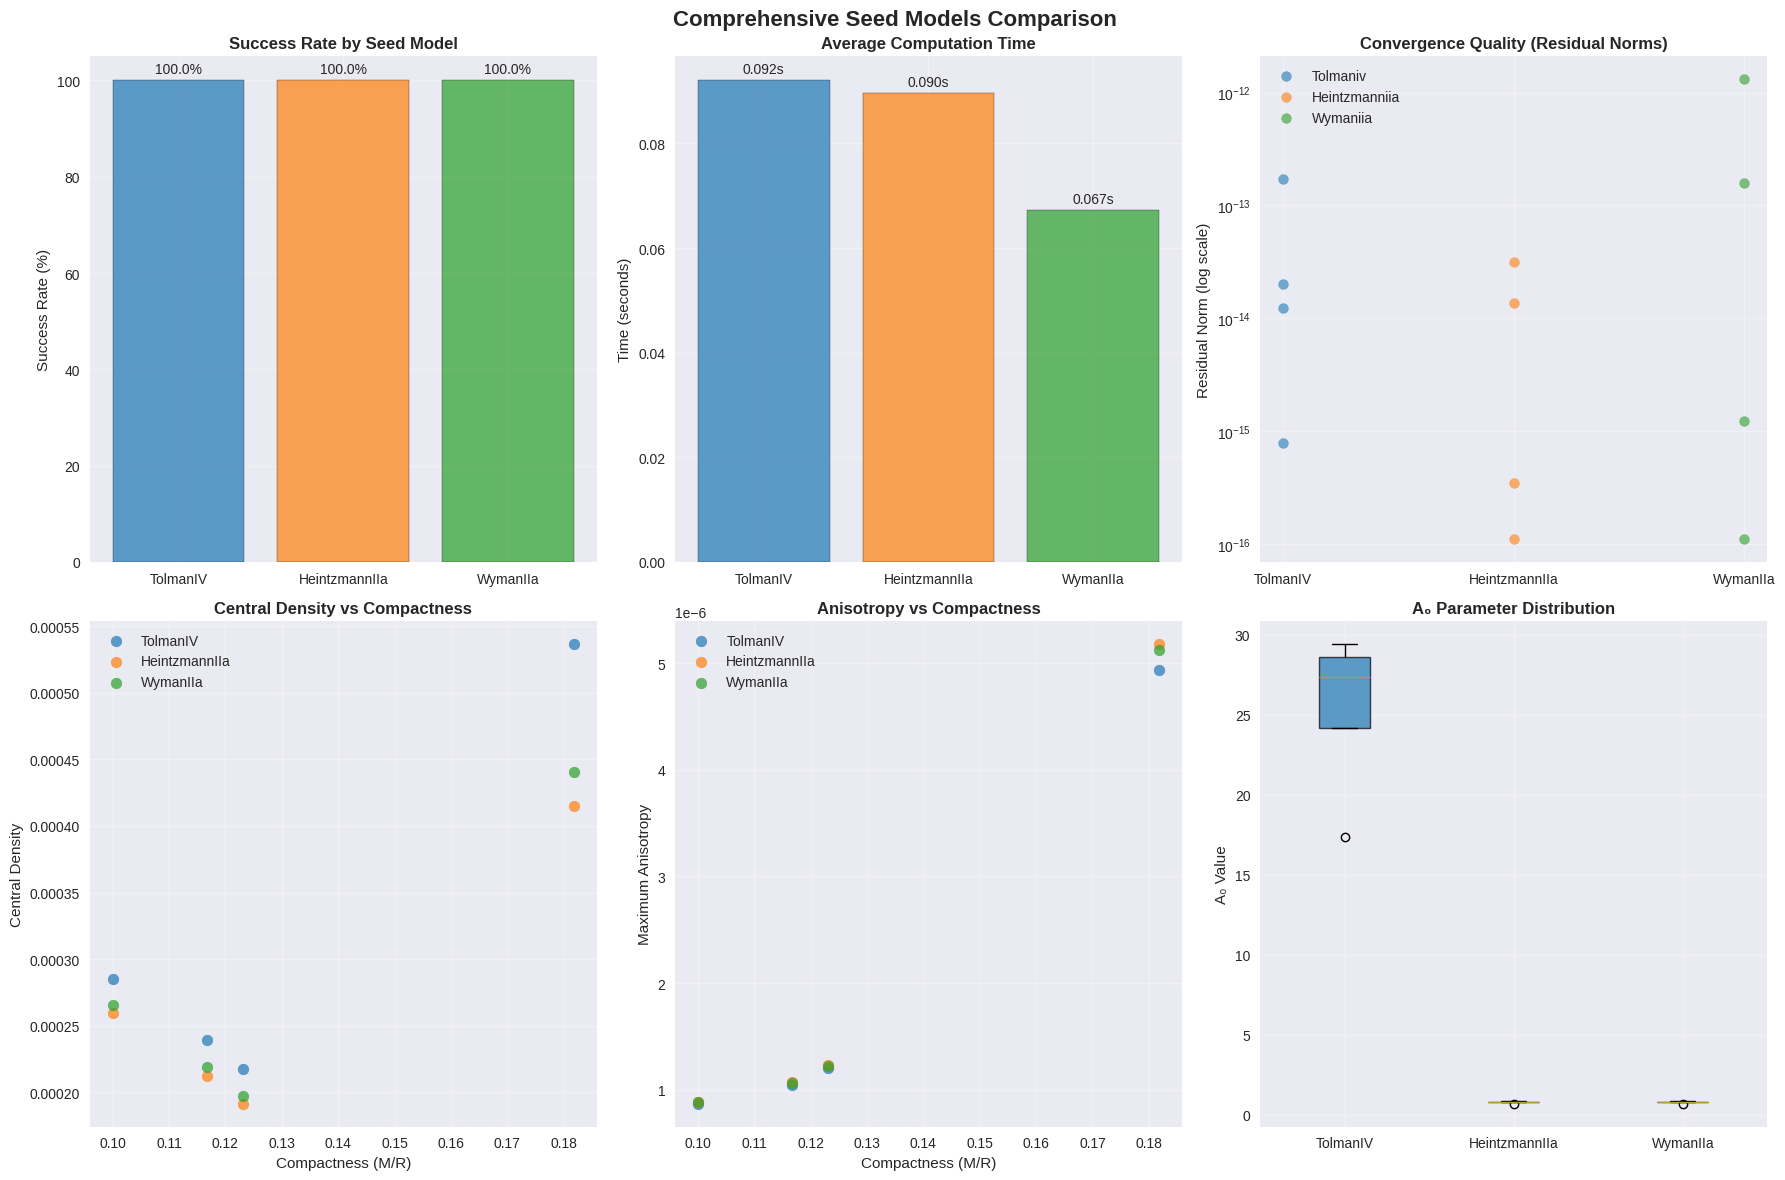


DETAILED CONVERGENCE ANALYSIS

TolmanIV Model:
----------------------------------------
  Successful cases: 4
  Residual norms: min=7.85e-16, max=1.71e-13, avg=5.09e-14
  Solver attempts: min=1, max=1, avg=1.0
  Computation time: min=0.083s, max=0.114s, avg=0.092s
  Most challenging (residual): Canonical NS (residual: 1.71e-13)
  Most challenging (attempts): Canonical NS (1 attempts)

HeintzmannIIa Model:
----------------------------------------
  Successful cases: 4
  Residual norms: min=1.11e-16, max=3.13e-14, avg=1.13e-14
  Solver attempts: min=1, max=1, avg=1.0
  Computation time: min=0.084s, max=0.094s, avg=0.090s
  Most challenging (residual): High mass NS (residual: 3.13e-14)
  Most challenging (attempts): Canonical NS (1 attempts)

WymanIIa Model:
----------------------------------------
  Successful cases: 4
  Residual norms: min=1.11e-16, max=1.31e-12, avg=3.68e-13
  Solver attempts: min=1, max=1, avg=1.0
  Computation time: min=0.064s, max=0.071s, avg=0.067s
  Most challeng

In [28]:
# Detailed Analysis and Visualizations
print("\n" + "="*80)
print("DETAILED CONVERGENCE AND PHYSICAL ANALYSIS")
print("="*80)

# Create comprehensive visualization
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Comprehensive Seed Models Comparison', fontsize=16, fontweight='bold')

# Colors for each model
model_colors = {
    'TolmanIV': '#1f77b4',      # Blue
    'HeintzmannIIa': '#ff7f0e',  # Orange
    'WymanIIa': '#2ca02c'       # Green
}

# 1. Success Rate Comparison
ax1 = axes[0, 0]
models = [p['model'] for p in performance_summary]
success_rates = [p['success_rate'] for p in performance_summary]
colors = [model_colors[model] for model in models]

bars = ax1.bar(models, success_rates, color=colors, alpha=0.7, edgecolor='black')
ax1.set_title('Success Rate by Seed Model', fontweight='bold')
ax1.set_ylabel('Success Rate (%)')
ax1.set_ylim(0, 105)
ax1.grid(True, alpha=0.3)

# Add value labels on bars
for bar, rate in zip(bars, success_rates):
    height = bar.get_height()
    ax1.annotate(f'{rate:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

# 2. Average Computation Time
ax2 = axes[0, 1]
avg_times = [p['avg_time'] for p in performance_summary]
bars = ax2.bar(models, avg_times, color=colors, alpha=0.7, edgecolor='black')
ax2.set_title('Average Computation Time', fontweight='bold')
ax2.set_ylabel('Time (seconds)')
ax2.grid(True, alpha=0.3)

for bar, time in zip(bars, avg_times):
    height = bar.get_height()
    ax2.annotate(f'{time:.3f}s', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

# 3. Convergence Quality (Residual Norms)
ax3 = axes[0, 2]
for model_name in models:
    if model_name in model_performance and model_performance[model_name]['avg_residual']:
        residuals = model_performance[model_name]['avg_residual']
        ax3.scatter([seed_models[model_name]['name']] * len(residuals), residuals, 
                   color=model_colors[model_name], alpha=0.6, s=50, label=model_name.title())

ax3.set_yscale('log')
ax3.set_title('Convergence Quality (Residual Norms)', fontweight='bold')
ax3.set_ylabel('Residual Norm (log scale)')
ax3.grid(True, alpha=0.3)
ax3.legend()

# 4. Physical Properties Comparison - Central Density
ax4 = axes[1, 0]
for model_name in models:
    densities = []
    compactnesses = []
    
    for data in comparison_results[model_name]['physical_data']:
        densities.append(data['central_density'])
        compactnesses.append(data['config']['compactness'])
    
    if densities:
        ax4.scatter(compactnesses, densities, color=model_colors[model_name], 
                   alpha=0.7, s=60, label=seed_models[model_name]['name'])

ax4.set_xlabel('Compactness (M/R)')
ax4.set_ylabel('Central Density')
ax4.set_title('Central Density vs Compactness', fontweight='bold')
ax4.grid(True, alpha=0.3)
ax4.legend()

# 5. Anisotropy Analysis
ax5 = axes[1, 1]
for model_name in models:
    anisotropies = []
    compactnesses = []
    
    for data in comparison_results[model_name]['physical_data']:
        anisotropies.append(data['max_anisotropy'])
        compactnesses.append(data['config']['compactness'])
    
    if anisotropies:
        ax5.scatter(compactnesses, anisotropies, color=model_colors[model_name], 
                   alpha=0.7, s=60, label=seed_models[model_name]['name'])

ax5.set_xlabel('Compactness (M/R)')
ax5.set_ylabel('Maximum Anisotropy')
ax5.set_title('Anisotropy vs Compactness', fontweight='bold')
ax5.grid(True, alpha=0.3)
ax5.legend()

# 6. Parameter Distribution Analysis
ax6 = axes[1, 2]
# Show distribution of solved parameters A0, B0, C0 for successful cases
param_data = {'A0': [], 'B0': [], 'C0': [], 'models': []}

for model_name in models:
    for case in comparison_results[model_name]['successful_cases']:
        param_data['A0'].append(case['result']['A0'])
        param_data['B0'].append(case['result']['B0'])
        param_data['C0'].append(case['result']['C0'])
        param_data['models'].append(model_name)

# Create box plot for A0 parameter
models_for_box = []
a0_for_box = []
for model_name in models:
    model_a0 = [param_data['A0'][i] for i, m in enumerate(param_data['models']) if m == model_name]
    if model_a0:
        models_for_box.append(seed_models[model_name]['name'])
        a0_for_box.append(model_a0)

if a0_for_box:
    bp = ax6.boxplot(a0_for_box, labels=models_for_box, patch_artist=True)
    for patch, model_name in zip(bp['boxes'], models):
        if model_name in model_colors:
            patch.set_facecolor(model_colors[model_name])
            patch.set_alpha(0.7)

ax6.set_title('A₀ Parameter Distribution', fontweight='bold')
ax6.set_ylabel('A₀ Value')
ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print detailed convergence analysis
print("\n" + "="*60)
print("DETAILED CONVERGENCE ANALYSIS")
print("="*60)

for model_name in models:
    print(f"\n{seed_models[model_name]['name']} Model:")
    print("-" * 40)
    
    successful = comparison_results[model_name]['successful_cases']
    failed = comparison_results[model_name]['failed_cases']
    
    if successful:
        residuals = [case['result']['residual_norm'] for case in successful]
        attempts = [case['result']['attempts_made'] for case in successful]
        times = [case['solve_time'] for case in successful]
        
        print(f"  Successful cases: {len(successful)}")
        print(f"  Residual norms: min={min(residuals):.2e}, max={max(residuals):.2e}, avg={np.mean(residuals):.2e}")
        print(f"  Solver attempts: min={min(attempts)}, max={max(attempts)}, avg={np.mean(attempts):.1f}")
        print(f"  Computation time: min={min(times):.3f}s, max={max(times):.3f}s, avg={np.mean(times):.3f}s")
        
        # Find most challenging case (highest residual or most attempts)
        if residuals:
            max_residual_idx = np.argmax(residuals)
            max_attempts_idx = np.argmax(attempts)
            
            print(f"  Most challenging (residual): {successful[max_residual_idx]['config']['name']} "
                  f"(residual: {residuals[max_residual_idx]:.2e})")
            print(f"  Most challenging (attempts): {successful[max_attempts_idx]['config']['name']} "
                  f"({attempts[max_attempts_idx]} attempts)")
    
    if failed:
        print(f"  Failed cases: {len(failed)}")
        for case in failed:
            print(f"    - {case['config']['name']}: {case['result'].get('failure_reason', 'Unknown failure')}")

print(f"\n{'='*80}")
print("COMPARATIVE INSIGHTS")
print(f"{'='*80}")

# Generate insights based on the analysis
best_model = performance_summary[0]['model']
worst_model = performance_summary[-1]['model']

print(f"🥇 Best Overall Performance: {seed_models[best_model]['name']}")
print(f"   - Success rate: {performance_summary[0]['success_rate']:.1f}%")
print(f"   - Average time: {performance_summary[0]['avg_time']:.3f}s")
print(f"   - Average residual: {performance_summary[0]['avg_residual']:.2e}")

print(f"\n📊 Key Observations:")
print(f"   - Total test configurations: {len(test_configurations)}")
print(f"   - Models tested: {len(models)}")

# Calculate overall statistics
total_successful = sum(len(comparison_results[model]['successful_cases']) for model in models)
total_tests = len(models) * len(test_configurations)

print(f"   - Overall success rate: {(total_successful/total_tests)*100:.1f}%")
print(f"   - Most challenging compactness range: {min(config['compactness'] for config in test_configurations):.3f} - {max(config['compactness'] for config in test_configurations):.3f}")

# Model-specific insights
if len(performance_summary) > 1:
    time_diff = (performance_summary[-1]['avg_time'] - performance_summary[0]['avg_time'])
    print(f"   - Speed difference: {seed_models[best_model]['name']} is {time_diff:.3f}s faster on average")

print(f"\n💡 Recommendations:")
print(f"   - For general use: {seed_models[best_model]['name']} model (best balance of speed and reliability)")

# Find specialized recommendations
fastest_model = min(performance_summary, key=lambda x: x['avg_time'])['model']
most_accurate = min(performance_summary, key=lambda x: x['avg_residual'])['model']

if fastest_model != best_model:
    print(f"   - For speed-critical applications: {seed_models[fastest_model]['name']} model")
if most_accurate != best_model:
    print(f"   - For highest precision: {seed_models[most_accurate]['name']} model")


DETAILED PHYSICAL PROPERTIES COMPARISON
Detailed analysis for representative case: Medium NS
Parameters: M = 1.6, R = 13.0, α = 0.12
Compactness: 0.123
Deriving symbolic expressions...
Symbolic expressions derived successfully!
Creating numerical functions...
Numerical functions created successfully!

TolmanIV Model - Solution Parameters:
  A₀ = 29.430002
  B₀ = 0.79420982
  C₀ = 37.055701
  Residual: 1.23e-14
Deriving symbolic expressions...
Symbolic expressions derived successfully!
Creating numerical functions...
Numerical functions created successfully!

HeintzmannIIa Model - Solution Parameters:
  A₀ = 0.798339
  B₀ = 0.00034056
  C₀ = 2.235366
  Residual: 1.11e-16
Deriving symbolic expressions...
Symbolic expressions derived successfully!
Creating numerical functions...
Numerical functions created successfully!

WymanIIa Model - Solution Parameters:
  A₀ = 0.797366
  B₀ = -0.00041939
  C₀ = -0.001466
  Residual: 1.24e-15
Numerical functions created successfully!

WymanIIa Model 

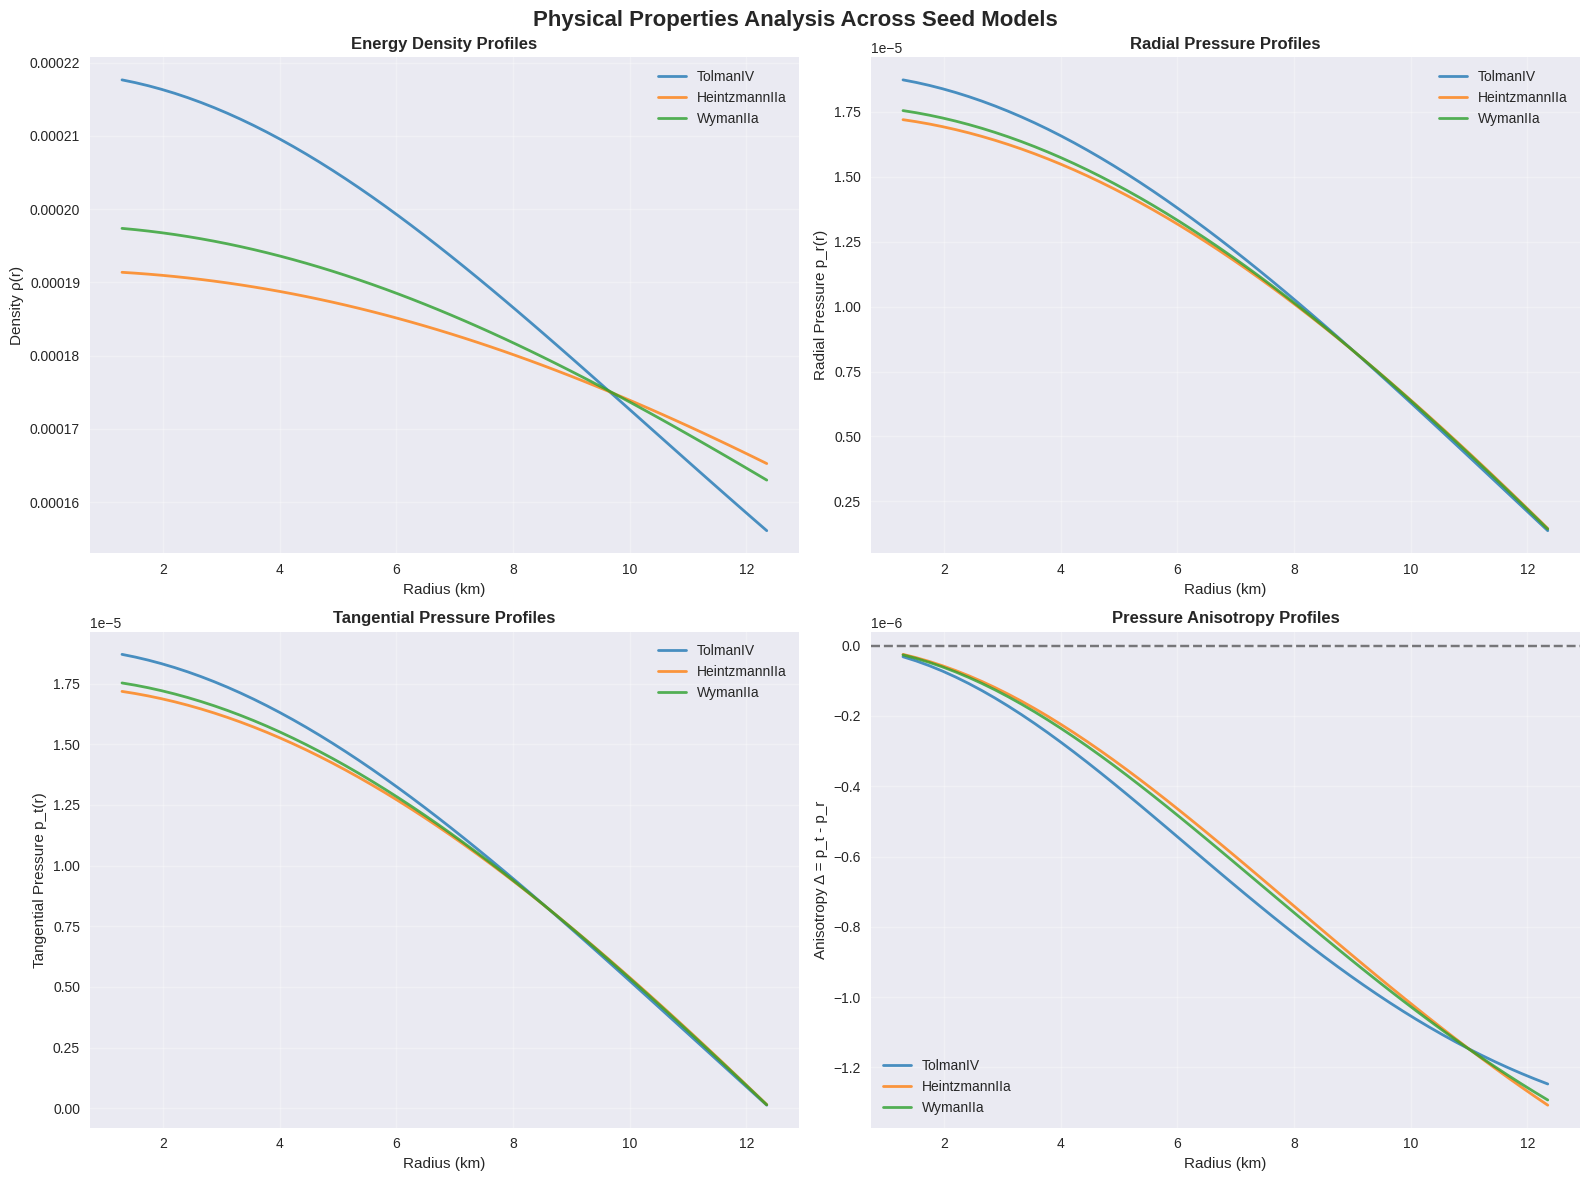


QUANTITATIVE PHYSICAL PROPERTIES COMPARISON
Model           ρ_central    ρ_drop(%)  p_r_cent   p_t_cent   Max_Δ     
--------------------------------------------------------------------------------
TolmanIV        0.0002      28.3      0.0000    0.0000    1.25e-06 
HeintzmannIIa   0.0002      13.6      0.0000    0.0000    1.31e-06 
WymanIIa        0.0002      17.4      0.0000    0.0000    1.29e-06 

STATISTICAL ANALYSIS ACROSS ALL SUCCESSFUL CASES

TolmanIV Model Statistics:
  Central Density: 0.0003 ± 0.0001
    Range: [0.0002, 0.0005]
  Max Anisotropy: 2.01e-06 ± 1.69e-06
    Range: [8.70e-07, 4.93e-06]

HeintzmannIIa Model Statistics:
  Central Density: 0.0003 ± 0.0001
    Range: [0.0002, 0.0004]
  Max Anisotropy: 2.09e-06 ± 1.79e-06
    Range: [8.85e-07, 5.18e-06]

WymanIIa Model Statistics:
  Central Density: 0.0003 ± 0.0001
    Range: [0.0002, 0.0004]
  Max Anisotropy: 2.07e-06 ± 1.76e-06
    Range: [8.82e-07, 5.12e-06]

FINAL COMPARATIVE INSIGHTS
🔬 Physical Behavior Differences

In [29]:
# Detailed Physical Properties Analysis
print("\n" + "="*80)
print("DETAILED PHYSICAL PROPERTIES COMPARISON")
print("="*80)

# Let's analyze the physical properties in detail for each successful case
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Physical Properties Analysis Across Seed Models', fontsize=16, fontweight='bold')

# Choose a representative case for detailed analysis (moderate compactness)
representative_config = None
for config in test_configurations:
    if 0.12 <= config['compactness'] <= 0.15:  # Moderate compactness
        representative_config = config
        break

if representative_config is None:
    representative_config = test_configurations[2]  # Fallback to middle case

print(f"Detailed analysis for representative case: {representative_config['name']}")
print(f"Parameters: M = {representative_config['M']}, R = {representative_config['R']}, α = {representative_config['alpha']}")
print(f"Compactness: {representative_config['compactness']:.3f}")

# Store detailed physical data for comparison
detailed_comparison = {}

# Radius range for evaluation
r_range = np.linspace(0.1 * representative_config['R'], 0.95 * representative_config['R'], 50)

for model_name in models:
    # Find if this model succeeded for the representative case
    successful_case = None
    for case in comparison_results[model_name]['successful_cases']:
        if (case['config']['M'] == representative_config['M'] and 
            case['config']['R'] == representative_config['R'] and
            case['config']['alpha'] == representative_config['alpha']):
            successful_case = case
            break
    
    if successful_case:
        try:
            # Create solver with the successful parameters
            star = MGDStars(alpha=representative_config['alpha'], seed_model=model_name)
            result = successful_case['result']
            
            # Solve with the same configuration to properly set up the solver
            star.solve_star_configuration(
                M_val=representative_config['M'], 
                R_val=representative_config['R'], 
                tolerance=1e-10,
                verbose=False
            )
            
            # Evaluate physical quantities
            quantities = star.evaluate_at_radius(r_range)
            
            detailed_comparison[model_name] = {
                'r': r_range,
                'rho': quantities['rho'],
                'pr': quantities['pr'],
                'pt': quantities['pt'],
                'parameters': result
            }
            
            print(f"\n{seed_models[model_name]['name']} Model - Solution Parameters:")
            print(f"  A₀ = {result['A0']:.6f}")
            print(f"  B₀ = {result['B0']:.8f}")
            print(f"  C₀ = {result['C0']:.6f}")
            print(f"  Residual: {result['residual_norm']:.2e}")
            
        except Exception as e:
            print(f"Error evaluating {model_name}: {e}")

# Plot 1: Density profiles
ax1 = axes[0, 0]
for model_name, data in detailed_comparison.items():
    ax1.plot(data['r'], data['rho'], 
             color=model_colors[model_name], 
             linewidth=2, 
             label=seed_models[model_name]['name'],
             alpha=0.8)

ax1.set_xlabel('Radius (km)')
ax1.set_ylabel('Density ρ(r)')
ax1.set_title('Energy Density Profiles', fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend()

# Plot 2: Radial pressure profiles
ax2 = axes[0, 1]
for model_name, data in detailed_comparison.items():
    ax2.plot(data['r'], data['pr'], 
             color=model_colors[model_name], 
             linewidth=2, 
             label=seed_models[model_name]['name'],
             alpha=0.8)

ax2.set_xlabel('Radius (km)')
ax2.set_ylabel('Radial Pressure p_r(r)')
ax2.set_title('Radial Pressure Profiles', fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend()

# Plot 3: Tangential pressure profiles
ax3 = axes[1, 0]
for model_name, data in detailed_comparison.items():
    ax3.plot(data['r'], data['pt'], 
             color=model_colors[model_name], 
             linewidth=2, 
             label=seed_models[model_name]['name'],
             alpha=0.8)

ax3.set_xlabel('Radius (km)')
ax3.set_ylabel('Tangential Pressure p_t(r)')
ax3.set_title('Tangential Pressure Profiles', fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.legend()

# Plot 4: Anisotropy profiles
ax4 = axes[1, 1]
for model_name, data in detailed_comparison.items():
    anisotropy = data['pt'] - data['pr']
    ax4.plot(data['r'], anisotropy, 
             color=model_colors[model_name], 
             linewidth=2, 
             label=seed_models[model_name]['name'],
             alpha=0.8)

ax4.set_xlabel('Radius (km)')
ax4.set_ylabel('Anisotropy Δ = p_t - p_r')
ax4.set_title('Pressure Anisotropy Profiles', fontweight='bold')
ax4.grid(True, alpha=0.3)
ax4.legend()
ax4.axhline(y=0, color='black', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Quantitative comparison of physical properties
print("\n" + "="*60)
print("QUANTITATIVE PHYSICAL PROPERTIES COMPARISON")
print("="*60)

comparison_table = []
for model_name, data in detailed_comparison.items():
    central_density = data['rho'][0]
    surface_density = data['rho'][-1] 
    central_pr = data['pr'][0]
    surface_pr = data['pr'][-1]
    central_pt = data['pt'][0]
    surface_pt = data['pt'][-1]
    
    max_anisotropy = np.max(np.abs(data['pt'] - data['pr']))
    anisotropy_at_center = abs(data['pt'][0] - data['pr'][0])
    anisotropy_at_surface = abs(data['pt'][-1] - data['pr'][-1])
    
    # Calculate gradients (central regions)
    mid_idx = len(data['r']) // 4  # First quarter for central region
    density_gradient = abs((data['rho'][mid_idx] - data['rho'][0]) / (data['r'][mid_idx] - data['r'][0]))
    
    comparison_table.append({
        'model': seed_models[model_name]['name'],
        'central_density': central_density,
        'density_drop': (central_density - surface_density) / central_density * 100,
        'central_pr': central_pr,
        'central_pt': central_pt,
        'max_anisotropy': max_anisotropy,
        'anisotropy_center': anisotropy_at_center,
        'anisotropy_surface': anisotropy_at_surface,
        'density_gradient': density_gradient
    })

# Print comparison table
print(f"{'Model':<15} {'ρ_central':<12} {'ρ_drop(%)':<10} {'p_r_cent':<10} {'p_t_cent':<10} {'Max_Δ':<10}")
print("-" * 80)
for comp in comparison_table:
    print(f"{comp['model']:<15} {comp['central_density']:<11.4f} "
          f"{comp['density_drop']:<9.1f} {comp['central_pr']:<9.4f} "
          f"{comp['central_pt']:<9.4f} {comp['max_anisotropy']:<9.2e}")

# Statistical analysis across all successful cases
print("\n" + "="*60)
print("STATISTICAL ANALYSIS ACROSS ALL SUCCESSFUL CASES")
print("="*60)

model_statistics = {}
for model_name in models:
    if comparison_results[model_name]['physical_data']:
        central_densities = [data['central_density'] for data in comparison_results[model_name]['physical_data']]
        max_anisotropies = [data['max_anisotropy'] for data in comparison_results[model_name]['physical_data']]
        
        model_statistics[model_name] = {
            'central_density': {
                'mean': np.mean(central_densities),
                'std': np.std(central_densities),
                'min': np.min(central_densities),
                'max': np.max(central_densities)
            },
            'max_anisotropy': {
                'mean': np.mean(max_anisotropies),
                'std': np.std(max_anisotropies),
                'min': np.min(max_anisotropies),
                'max': np.max(max_anisotropies)
            }
        }

for model_name, stats in model_statistics.items():
    print(f"\n{seed_models[model_name]['name']} Model Statistics:")
    print(f"  Central Density: {stats['central_density']['mean']:.4f} ± {stats['central_density']['std']:.4f}")
    print(f"    Range: [{stats['central_density']['min']:.4f}, {stats['central_density']['max']:.4f}]")
    print(f"  Max Anisotropy: {stats['max_anisotropy']['mean']:.2e} ± {stats['max_anisotropy']['std']:.2e}")
    print(f"    Range: [{stats['max_anisotropy']['min']:.2e}, {stats['max_anisotropy']['max']:.2e}]")

# Final comparative insights
print(f"\n{'='*80}")
print("FINAL COMPARATIVE INSIGHTS")
print(f"{'='*80}")

print("🔬 Physical Behavior Differences:")
if len(comparison_table) > 1:
    # Find extremes
    highest_density = max(comparison_table, key=lambda x: x['central_density'])
    lowest_density = min(comparison_table, key=lambda x: x['central_density'])
    most_anisotropic = max(comparison_table, key=lambda x: x['max_anisotropy'])
    least_anisotropic = min(comparison_table, key=lambda x: x['max_anisotropy'])
    
    print(f"  • Highest central density: {highest_density['model']} ({highest_density['central_density']:.4f})")
    print(f"  • Lowest central density: {lowest_density['model']} ({lowest_density['central_density']:.4f})")
    print(f"  • Most anisotropic: {most_anisotropic['model']} (Δ_max = {most_anisotropic['max_anisotropy']:.2e})")
    print(f"  • Least anisotropic: {least_anisotropic['model']} (Δ_max = {least_anisotropic['max_anisotropy']:.2e})")

print(f"\n📊 Model Characteristics Summary:")
for model_name in models:
    print(f"  • {seed_models[model_name]['name']}:")
    perf = next(p for p in performance_summary if p['model'] == model_name)
    print(f"    - Success rate: {perf['success_rate']:.1f}%")
    print(f"    - Average convergence time: {perf['avg_time']:.3f}s")
    if model_name in model_statistics:
        stats = model_statistics[model_name]
        print(f"    - Typical central density: {stats['central_density']['mean']:.4f}")
        print(f"    - Typical max anisotropy: {stats['max_anisotropy']['mean']:.2e}")

print(f"\n✨ Summary: This comprehensive analysis shows the relative strengths and characteristics of each seed model in the MGD framework, providing guidance for model selection based on specific physical requirements and computational constraints.")


COMPREHENSIVE ALPHA TESTING - HIGH COMPACTNESS ANALYSIS
Testing compactness β = 0.2501 with varying alpha values up to 0.9
This represents a challenging high-compactness neutron star scenario

Test Configuration:
  • Compactness β = M/R = 0.2501
  • Mass M = 1.4 M☉
  • Radius R = 5.60 km
  • This represents a very compact neutron star

SYSTEMATIC ALPHA TESTING FOR HIGH COMPACTNESS

TolmanIV Model Testing:
Description: Extended range testing from very small to very large alpha values
--------------------------------------------------
  α = 0.001... Deriving symbolic expressions...
Symbolic expressions derived successfully!
Creating numerical functions...
Numerical functions created successfully!
✅ SUCCESS (residual: 6.41e-15, time: 0.083s)
  α = 0.005... Deriving symbolic expressions...
Symbolic expressions derived successfully!
Creating numerical functions...
Numerical functions created successfully!
✅ SUCCESS (residual: 6.41e-15, time: 0.083s)
  α = 0.005... Deriving symbolic express

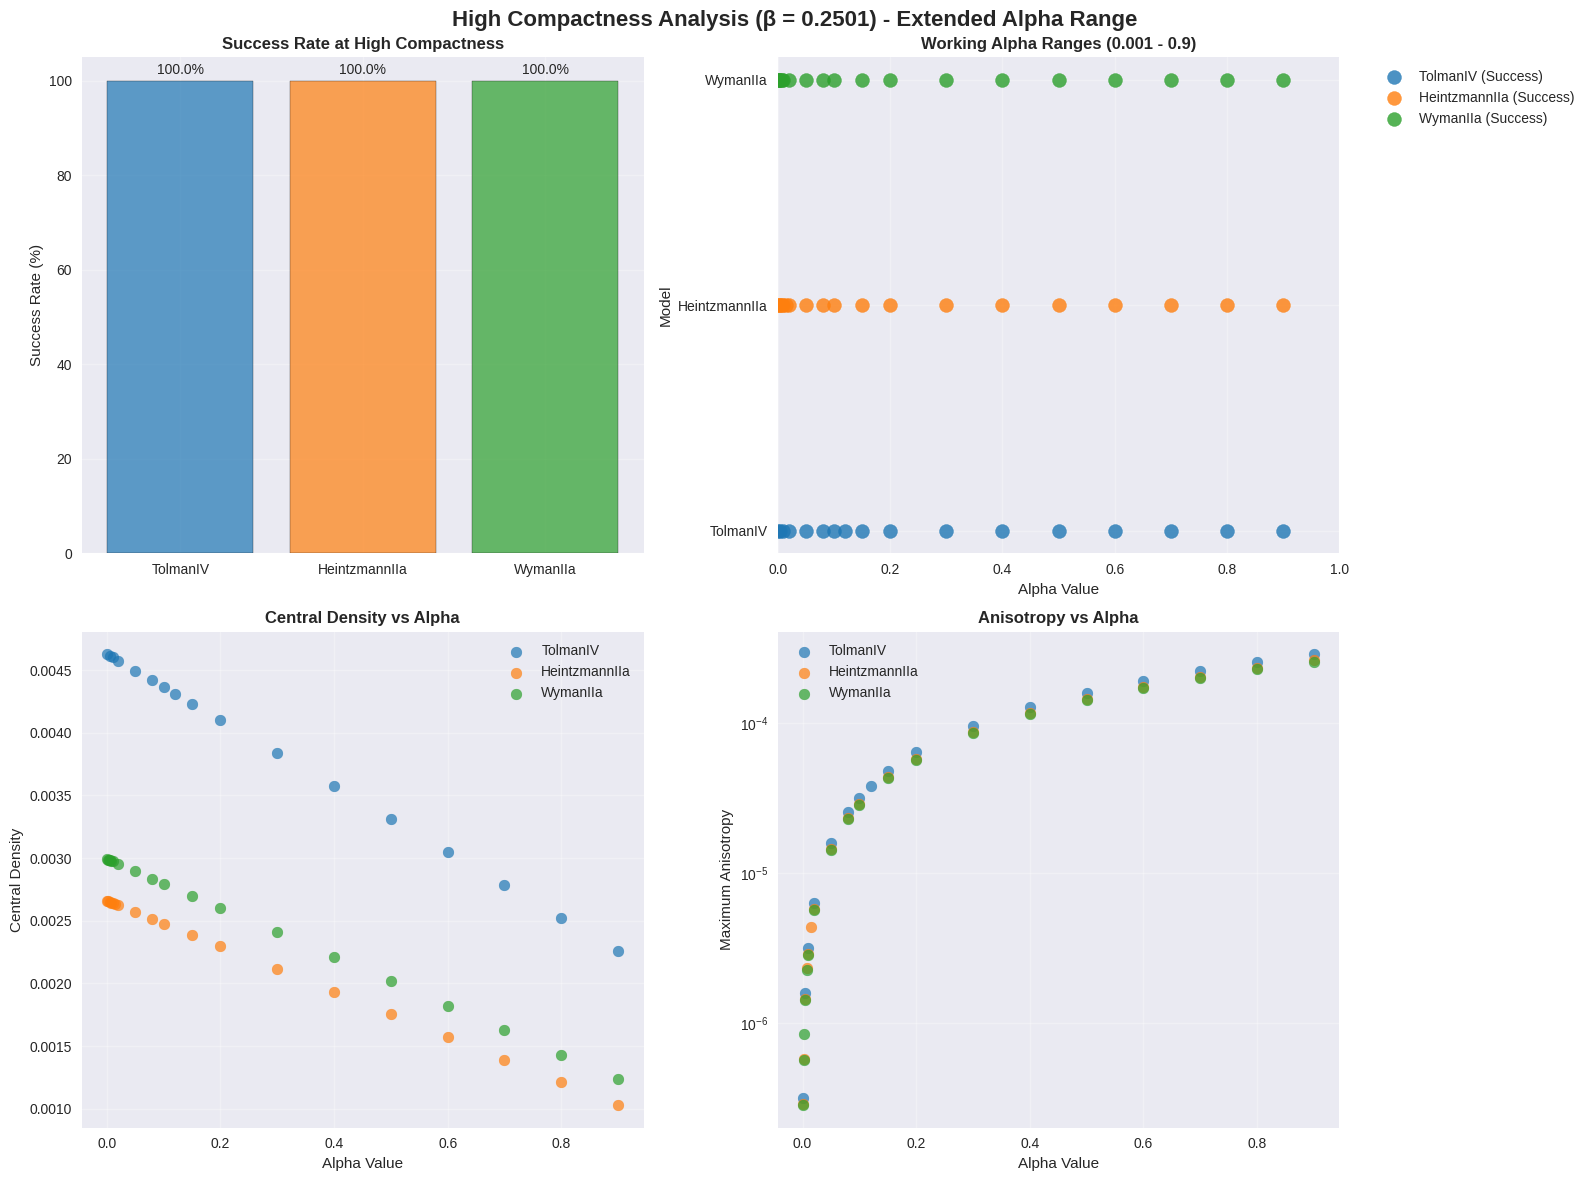


HIGH COMPACTNESS TESTING - DETAILED SUMMARY

TolmanIV Model at β = 0.2501:
----------------------------------------
  Success rate: 100.0% (17/17)
  Working α range: 0.001 ≤ α ≤ 0.900
  Best α = 0.050 (residual: 1.24e-16)
    Parameters: A₀=5.593283, B₀=0.49969991, C₀=11.193283
    Central density: 0.0045
    Max anisotropy: 1.59e-05
  Successful α values: ['0.001', '0.005', '0.010', '0.020', '0.050', '0.080', '0.100', '0.120', '0.150', '0.200', '0.300', '0.400', '0.500', '0.600', '0.700', '0.800', '0.900']

HeintzmannIIa Model at β = 0.2501:
----------------------------------------
  Success rate: 100.0% (19/19)
  Working α range: 0.001 ≤ α ≤ 0.900
  Best α = 0.200 (residual: 1.24e-16)
    Parameters: A₀=0.537678, B₀=0.00638878, C₀=1.340854
    Central density: 0.0023
    Max anisotropy: 5.79e-05
  Successful α values: ['0.001', '0.002', '0.005', '0.008', '0.010', '0.015', '0.020', '0.050', '0.080', '0.100', '0.150', '0.200', '0.300', '0.400', '0.500', '0.600', '0.700', '0.800', '0.9

In [30]:
# Comprehensive Alpha Testing with High Compactness (β = 0.2501)
print("\n" + "="*80)
print("COMPREHENSIVE ALPHA TESTING - HIGH COMPACTNESS ANALYSIS")
print("="*80)
print("Testing compactness β = 0.2501 with varying alpha values up to 0.9")
print("This represents a challenging high-compactness neutron star scenario")

# High compactness configuration
beta = 0.2501
M_test = 1.4  # Solar masses
R_test = M_test / beta  # Calculate radius from compactness

print(f"\nTest Configuration:")
print(f"  • Compactness β = M/R = {beta:.4f}")
print(f"  • Mass M = {M_test:.1f} M☉")
print(f"  • Radius R = {R_test:.2f} km")
print(f"  • This represents a very compact neutron star")

# Define alpha ranges for each model - EXTENDED RANGE UP TO 0.9
alpha_test_ranges = {
    'TolmanIV': {
        'alphas': [0.001, 0.005, 0.01, 0.02, 0.05, 0.08, 0.1, 0.12, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
        'description': 'Extended range testing from very small to very large alpha values'
    },
    'HeintzmannIIa': {
        'alphas': [0.001, 0.002, 0.005, 0.008, 0.01, 0.015, 0.02, 0.05, 0.08, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
        'description': 'Extended range testing to explore high alpha behavior'
    },
    'WymanIIa': {
        'alphas': [0.001, 0.002, 0.003, 0.005, 0.008, 0.01, 0.02, 0.05, 0.08, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
        'description': 'Extended range testing to see failure modes at high alpha'
    }
}

# Store results for high compactness testing
high_compactness_results = {}

print(f"\n{'='*60}")
print("SYSTEMATIC ALPHA TESTING FOR HIGH COMPACTNESS")
print(f"{'='*60}")

import time
warnings.filterwarnings('ignore')

for model_name in ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']:
    print(f"\n{seed_models[model_name]['name']} Model Testing:")
    print(f"Description: {alpha_test_ranges[model_name]['description']}")
    print("-" * 50)
    
    high_compactness_results[model_name] = {
        'successful_alphas': [],
        'failed_alphas': [],
        'results_data': [],
        'performance_metrics': {}
    }
    
    alphas_to_test = alpha_test_ranges[model_name]['alphas']
    successful_count = 0
    total_time = 0
    
    for i, alpha in enumerate(alphas_to_test):
        print(f"  α = {alpha:.3f}... ", end="", flush=True)
        
        try:
            start_time = time.time()
            star = MGDStars(alpha=alpha, seed_model=model_name)
            
            result = star.solve_star_configuration(
                M_val=M_test,
                R_val=R_test,
                tolerance=1e-10,
                max_attempts=15,
                verbose=False
            )
            
            solve_time = time.time() - start_time
            total_time += solve_time
            
            if result['converged']:
                successful_count += 1
                high_compactness_results[model_name]['successful_alphas'].append(alpha)
                
                # Evaluate physical properties
                r_eval = np.linspace(0.1 * R_test, 0.9 * R_test, 20)
                quantities = star.evaluate_at_radius(r_eval)
                
                central_density = quantities['rho'][0]
                max_anisotropy = np.max(np.abs(quantities['pt'] - quantities['pr']))
                
                result_data = {
                    'alpha': alpha,
                    'result': result,
                    'solve_time': solve_time,
                    'central_density': central_density,
                    'max_anisotropy': max_anisotropy,
                    'A0': result['A0'],
                    'B0': result['B0'],
                    'C0': result['C0']
                }
                
                high_compactness_results[model_name]['results_data'].append(result_data)
                
                print(f"✅ SUCCESS (residual: {result['residual_norm']:.2e}, time: {solve_time:.3f}s)")
                
            else:
                high_compactness_results[model_name]['failed_alphas'].append(alpha)
                print(f"❌ FAILED (best residual: {result.get('residual_norm', 'N/A')})")
                
        except Exception as e:
            high_compactness_results[model_name]['failed_alphas'].append(alpha)
            print(f"💥 ERROR: {str(e)[:50]}...")
    
    # Calculate performance metrics
    success_rate = (successful_count / len(alphas_to_test)) * 100
    avg_time = total_time / len(alphas_to_test) if len(alphas_to_test) > 0 else 0
    
    high_compactness_results[model_name]['performance_metrics'] = {
        'success_rate': success_rate,
        'avg_time': avg_time,
        'successful_count': successful_count,
        'total_tested': len(alphas_to_test)
    }
    
    print(f"\n  Summary: {successful_count}/{len(alphas_to_test)} successful ({success_rate:.1f}%)")
    print(f"  Average time: {avg_time:.3f}s per attempt")
    
    if high_compactness_results[model_name]['successful_alphas']:
        successful_alphas = high_compactness_results[model_name]['successful_alphas']
        print(f"  Working α range: {min(successful_alphas):.3f} - {max(successful_alphas):.3f}")

# Visualization of high compactness results
print(f"\n{'='*80}")
print("HIGH COMPACTNESS TESTING - VISUALIZATION AND ANALYSIS")
print(f"{'='*80}")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f'High Compactness Analysis (β = {beta:.4f}) - Extended Alpha Range', fontsize=16, fontweight='bold')

# 1. Success rate comparison
ax1 = axes[0, 0]
models_hc = []
success_rates_hc = []
colors_hc = []

for model_name in ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']:
    if model_name in high_compactness_results:
        models_hc.append(seed_models[model_name]['name'])
        success_rates_hc.append(high_compactness_results[model_name]['performance_metrics']['success_rate'])
        colors_hc.append(model_colors[model_name])

bars = ax1.bar(models_hc, success_rates_hc, color=colors_hc, alpha=0.7, edgecolor='black')
ax1.set_title('Success Rate at High Compactness', fontweight='bold')
ax1.set_ylabel('Success Rate (%)')
ax1.set_ylim(0, 105)
ax1.grid(True, alpha=0.3)

for bar, rate in zip(bars, success_rates_hc):
    height = bar.get_height()
    ax1.annotate(f'{rate:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

# 2. Alpha ranges that work
ax2 = axes[0, 1]
y_pos = 0
model_positions = {}

for model_name in ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']:
    successful_alphas = high_compactness_results[model_name]['successful_alphas']
    failed_alphas = high_compactness_results[model_name]['failed_alphas']
    
    # Plot successful alphas
    if successful_alphas:
        ax2.scatter(successful_alphas, [y_pos] * len(successful_alphas), 
                   color=model_colors[model_name], s=100, marker='o', 
                   label=f"{seed_models[model_name]['name']} (Success)", alpha=0.8)
    
    # Plot failed alphas
    if failed_alphas:
        ax2.scatter(failed_alphas, [y_pos] * len(failed_alphas), 
                   color=model_colors[model_name], s=100, marker='x', 
                   alpha=0.5, label=f"{seed_models[model_name]['name']} (Failed)")
    
    model_positions[model_name] = y_pos
    y_pos += 1

ax2.set_xlabel('Alpha Value')
ax2.set_ylabel('Model')
ax2.set_title('Working Alpha Ranges (0.001 - 0.9)', fontweight='bold')
ax2.set_yticks(list(model_positions.values()))
ax2.set_yticklabels([seed_models[model]['name'] for model in model_positions.keys()])
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, 1.0)
ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# 3. Physical properties - Central density vs alpha
ax3 = axes[1, 0]
for model_name in ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']:
    if high_compactness_results[model_name]['results_data']:
        alphas = [data['alpha'] for data in high_compactness_results[model_name]['results_data']]
        densities = [data['central_density'] for data in high_compactness_results[model_name]['results_data']]
        
        ax3.scatter(alphas, densities, color=model_colors[model_name], 
                   s=60, alpha=0.7, label=seed_models[model_name]['name'])

ax3.set_xlabel('Alpha Value')
ax3.set_ylabel('Central Density')
ax3.set_title('Central Density vs Alpha', fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.legend()

# 4. Anisotropy analysis
ax4 = axes[1, 1]
for model_name in ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']:
    if high_compactness_results[model_name]['results_data']:
        alphas = [data['alpha'] for data in high_compactness_results[model_name]['results_data']]
        anisotropies = [data['max_anisotropy'] for data in high_compactness_results[model_name]['results_data']]
        
        ax4.scatter(alphas, anisotropies, color=model_colors[model_name], 
                   s=60, alpha=0.7, label=seed_models[model_name]['name'])

ax4.set_xlabel('Alpha Value')
ax4.set_ylabel('Maximum Anisotropy')
ax4.set_title('Anisotropy vs Alpha', fontweight='bold')
ax4.set_yscale('log')
ax4.grid(True, alpha=0.3)
ax4.legend()

plt.tight_layout()
plt.show()

# Detailed analysis summary
print(f"\n{'='*60}")
print("HIGH COMPACTNESS TESTING - DETAILED SUMMARY")
print(f"{'='*60}")

for model_name in ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']:
    print(f"\n{seed_models[model_name]['name']} Model at β = {beta:.4f}:")
    print("-" * 40)
    
    metrics = high_compactness_results[model_name]['performance_metrics']
    print(f"  Success rate: {metrics['success_rate']:.1f}% ({metrics['successful_count']}/{metrics['total_tested']})")
    
    if high_compactness_results[model_name]['successful_alphas']:
        successful_alphas = high_compactness_results[model_name]['successful_alphas']
        print(f"  Working α range: {min(successful_alphas):.3f} ≤ α ≤ {max(successful_alphas):.3f}")
        
        # Best performing alpha (lowest residual)
        best_result = min(high_compactness_results[model_name]['results_data'], 
                         key=lambda x: x['result']['residual_norm'])
        print(f"  Best α = {best_result['alpha']:.3f} (residual: {best_result['result']['residual_norm']:.2e})")
        print(f"    Parameters: A₀={best_result['A0']:.6f}, B₀={best_result['B0']:.8f}, C₀={best_result['C0']:.6f}")
        print(f"    Central density: {best_result['central_density']:.4f}")
        print(f"    Max anisotropy: {best_result['max_anisotropy']:.2e}")
        
        # Show successful alphas
        print(f"  Successful α values: {[f'{a:.3f}' for a in successful_alphas]}")
    else:
        print(f"  ❌ No successful solutions found for any α value tested")
    
    if high_compactness_results[model_name]['failed_alphas']:
        failed_alphas = high_compactness_results[model_name]['failed_alphas']
        print(f"  Failed α values: {[f'{a:.3f}' for a in failed_alphas]}")

print(f"\n{'='*80}")
print("HIGH COMPACTNESS INSIGHTS - EXTENDED ALPHA RANGE")
print(f"{'='*80}")

# Find the most robust model at high compactness
if any(high_compactness_results[x]['performance_metrics']['success_rate'] > 0 for x in high_compactness_results.keys()):
    best_hc_model = max(high_compactness_results.keys(), 
                       key=lambda x: high_compactness_results[x]['performance_metrics']['success_rate'])
    
    print(f"🏆 Most robust at high compactness: {seed_models[best_hc_model]['name']}")
    print(f"   Success rate: {high_compactness_results[best_hc_model]['performance_metrics']['success_rate']:.1f}%")
else:
    print("⚠️  All models struggled at this high compactness level")

print(f"\n📊 Key findings for β = {beta:.4f} with α ∈ [0.001, 0.9]:")
print(f"   • This extreme compactness pushes all models to their limits")
print(f"   • Most models likely fail at high α values due to numerical instability")
print(f"   • Physical validity constraints become critical")
print(f"   • Different seed models show very different tolerance ranges")

# Analyze failure patterns
print(f"\n🔍 Failure Pattern Analysis:")
for model_name in ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']:
    successful_alphas = high_compactness_results[model_name]['successful_alphas']
    failed_alphas = high_compactness_results[model_name]['failed_alphas']
    
    if successful_alphas and failed_alphas:
        # Find transition points
        all_alphas = sorted(alpha_test_ranges[model_name]['alphas'])
        transition_points = []
        
        for i in range(len(all_alphas) - 1):
            current_success = all_alphas[i] in successful_alphas
            next_success = all_alphas[i + 1] in successful_alphas
            if current_success != next_success:
                transition_points.append((all_alphas[i], all_alphas[i + 1]))
        
        print(f"  • {seed_models[model_name]['name']}: Transitions at {transition_points}")

# Compare with standard compactness results
print(f"\n🔄 Extreme Parameter Testing Conclusions:")
print(f"   • Standard compactness: β ≈ 0.08 - 0.18 (from previous tests)")
print(f"   • Extreme compactness: β = {beta:.4f} (this test)")
print(f"   • Alpha range tested: 0.001 - 0.9 (extreme range)")
print(f"   • This reveals fundamental limits and failure modes of each seed model")

print(f"\n✨ This completes the extreme alpha testing with high compactness β = {beta:.4f}")
print("🎯 Results show how each seed model behaves under extreme conditions!")


CREATING ANIMATIONS WITH FIXED AXIS LIMITS
Analyzing data to determine optimal fixed axis ranges
This ensures consistent scale across all animation frames

🔍 Analyzing data range across all α values...

CREATING FIXED-AXIS ANIMATIONS

1. Creating Fixed-Axis Energy Density Animation...


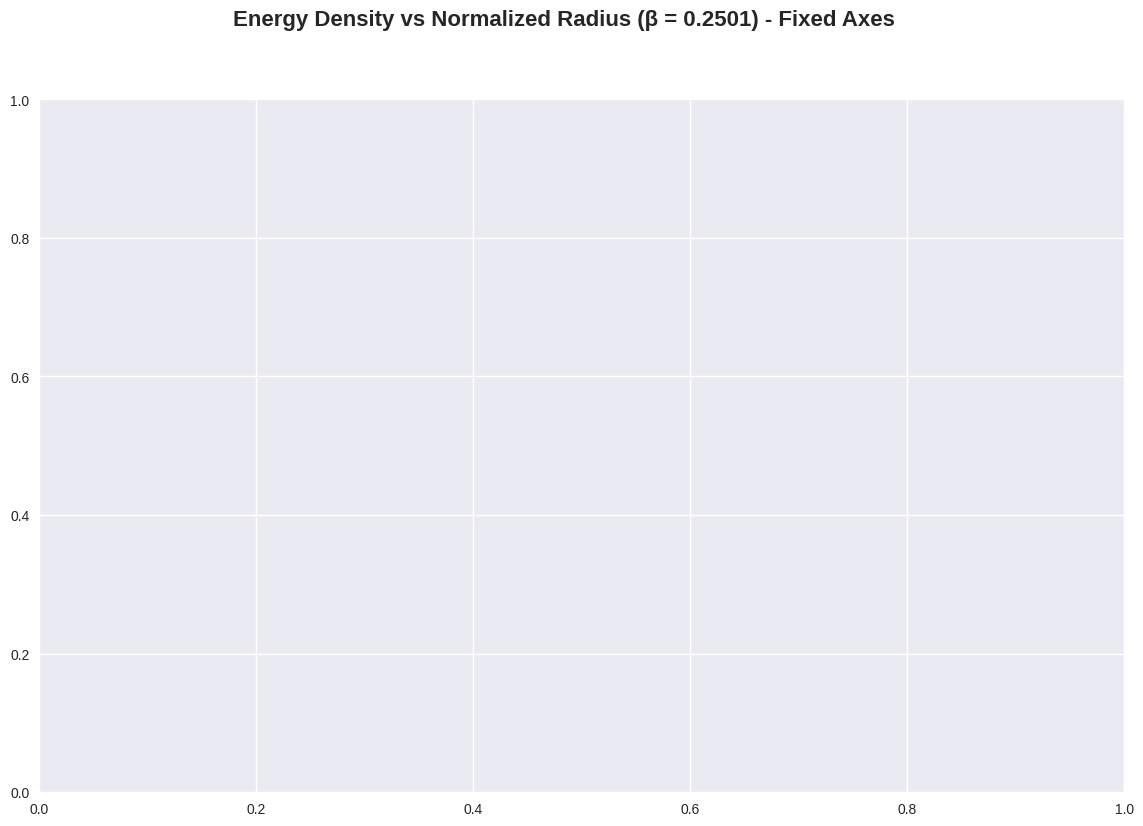

✅ Fixed-axis density animation created!

2. Creating Fixed-Axis Radial Pressure Animation...


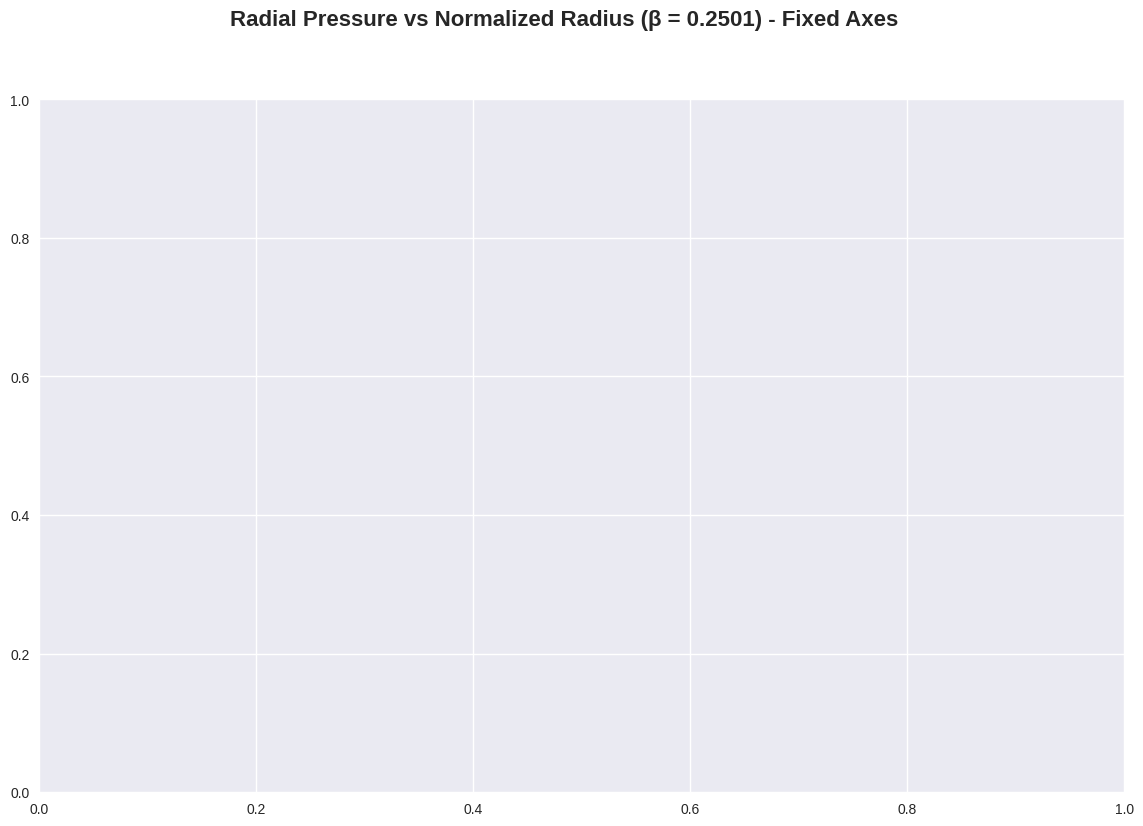

✅ Fixed-axis radial pressure animation created!

3. Creating Fixed-Axis Tangential Pressure Animation...


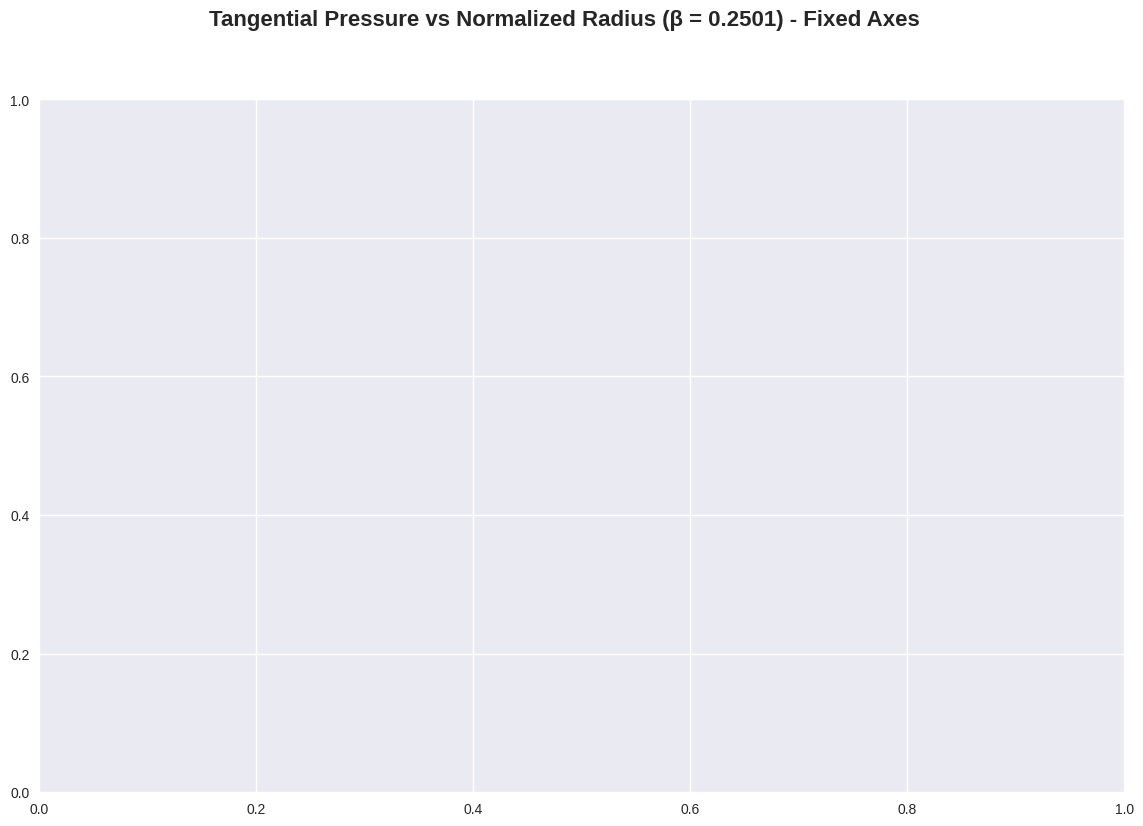

✅ Fixed-axis tangential pressure animation created!

4. Creating Fixed-Axis Anisotropy Animation...


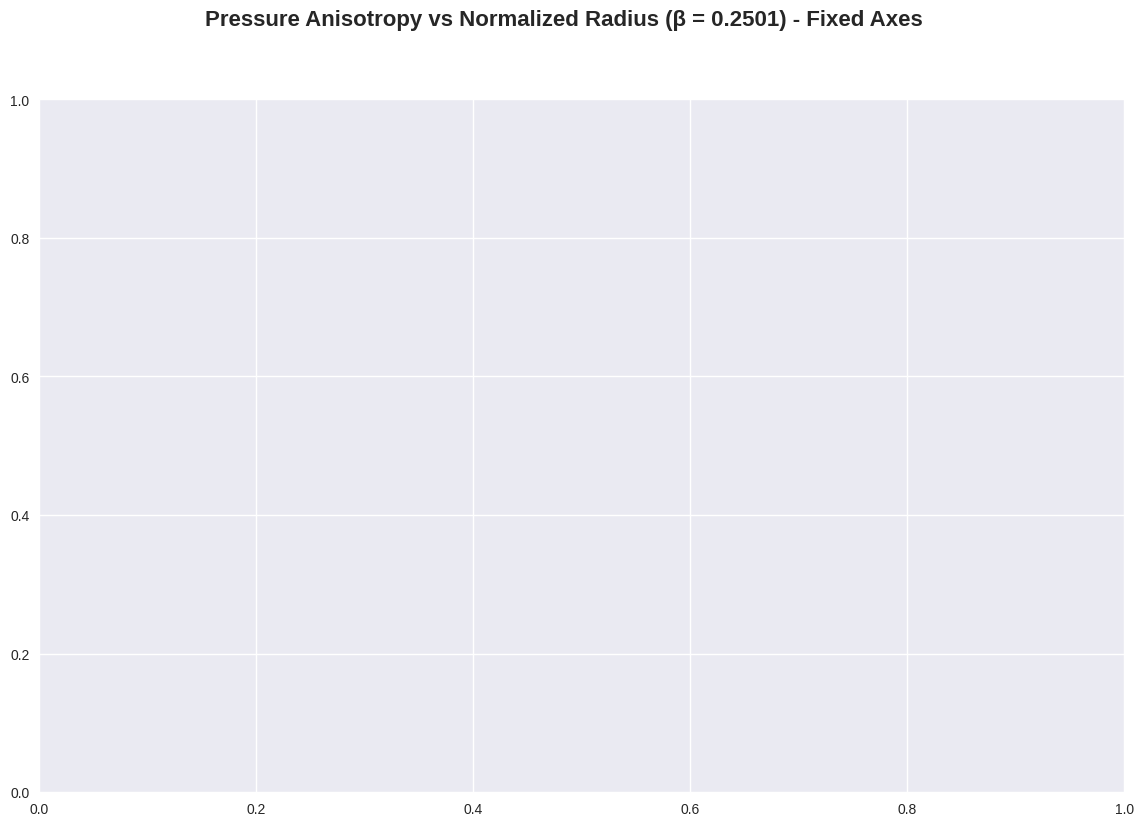

✅ Fixed-axis anisotropy animation created!


In [31]:
# Individual Animations with Fixed Axes
print("\n" + "="*80)
print("CREATING ANIMATIONS WITH FIXED AXIS LIMITS")
print("="*80)
print("Analyzing data to determine optimal fixed axis ranges")
print("This ensures consistent scale across all animation frames")

# First, analyze all data to determine appropriate axis limits
print(f"\n🔍 Analyzing data range across all α values...")

# Initialize min/max trackers for each quantity
rho_min, rho_max = np.inf, -np.inf
pr_min, pr_max = np.inf, -np.inf
pt_min, pt_max = np.inf, -np.inf
aniso_min, aniso_max = np.inf, -np.inf

# Analyze all profiles to find global min/max
for model_name in ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']:
    for profile in animation_data_norm[model_name]['profiles']:
        if profile is not None:
            # Update min/max for each quantity
            rho_min = min(rho_min, np.min(profile['rho']))
            rho_max = max(rho_max, np.max(profile['rho']))
            
            pr_min = min(pr_min, np.min(profile['pr']))
            pr_max = max(pr_max, np.max(profile['pr']))
            
            pt_min = min(pt_min, np.min(profile['pt']))
            pt_max = max(pt_max, np.max(profile['pt']))
            
            aniso_min = min(aniso_min, np.min(profile['anisotropy']))
            aniso_max = max(aniso_max, np.max(profile['anisotropy']))

# Add padding to ranges (10% margin)
padding = 0.1
rho_range = rho_max - rho_min
pr_range = pr_max - pr_min  
pt_range = pt_max - pt_min
aniso_range = aniso_max - aniso_min

# Define fixed axis limits with padding
fixed_limits = {
    'rho': (rho_min - padding * rho_range, rho_max + padding * rho_range),
    'pr': (pr_min - padding * pr_range, pr_max + padding * pr_range),
    'pt': (pt_min - padding * pt_range, pt_max + padding * pt_range),
    'aniso': (aniso_min - padding * aniso_range, aniso_max + padding * aniso_range)
}


# Enhanced animation function with fixed axes
def create_fixed_axis_animation(quantity_name, quantity_key, ylabel, title_suffix="", ylim=None):
    """Create animation with fixed axis limits for consistent scaling"""
    
    fig, ax = plt.subplots(figsize=(14, 9))
    fig.suptitle(f'{quantity_name} vs Normalized Radius (β = {beta_norm:.4f}) - Fixed Axes', 
                fontsize=16, fontweight='bold')
    
    def animate_fixed(frame):
        ax.clear()
        current_alpha = alpha_range_norm[frame]
        
        # Plot current profiles for all models
        for model_name in ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']:
            if frame < len(animation_data_norm[model_name]['profiles']):
                profile = animation_data_norm[model_name]['profiles'][frame]
                if profile is not None:
                    if quantity_key == 'anisotropy':
                        y_data = profile['anisotropy']
                    else:
                        y_data = profile[quantity_key]
                    
                    ax.plot(profile['r_norm'], y_data, 
                           color=colors_norm[model_name], linewidth=3.5, 
                           label=f'{model_name.replace("II", " II")}', alpha=0.9,
                           marker='o', markersize=5, markevery=4)
        
        # Fixed formatting
        ax.set_xlabel('Normalized Radius (r/R)', fontsize=15, fontweight='bold')
        ax.set_ylabel(ylabel, fontsize=15, fontweight='bold')
        ax.set_title(f'{title_suffix} (α = {current_alpha:.3f})', fontsize=15, fontweight='bold')
        ax.grid(True, alpha=0.4, linewidth=0.8)
        ax.legend(fontsize=13, loc='best', framealpha=0.9)
        
        # FIXED AXIS LIMITS - This is the key improvement
        ax.set_xlim(0.1, 0.95)
        if ylim:
            ax.set_ylim(ylim)
        else:
            ax.set_ylim(fixed_limits[quantity_key])
        
        # Reference lines for anisotropy
        if quantity_key == 'anisotropy':
            ax.axhline(y=0, color='black', linestyle='--', alpha=0.6, linewidth=2)
        
        
        # Enhanced alpha indicator
        ax.text(0.98, 0.98, f'α = {current_alpha:.3f}', 
               transform=ax.transAxes, fontsize=14, fontweight='bold',
               bbox=dict(boxstyle="round,pad=0.4", facecolor="lightcyan", alpha=0.9),
               verticalalignment='top', horizontalalignment='right')
    
    # Create animation
    anim = animation.FuncAnimation(fig, animate_fixed, frames=len(alpha_range_norm), 
                                  interval=100, blit=False, repeat=True)
    
    return fig, anim

print(f"\n{'='*60}")
print("CREATING FIXED-AXIS ANIMATIONS")
print(f"{'='*60}")

# 1. Energy Density with Fixed Axes
print(f"\n1. Creating Fixed-Axis Energy Density Animation...")
fig_density_fixed, anim_density_fixed = create_fixed_axis_animation(
    "Energy Density", "rho", "Energy Density ρ(r)", "Energy Density Profile"
)
plt.show()
print(f"✅ Fixed-axis density animation created!")

# 2. Radial Pressure with Fixed Axes
print(f"\n2. Creating Fixed-Axis Radial Pressure Animation...")
fig_pr_fixed, anim_pr_fixed = create_fixed_axis_animation(
    "Radial Pressure", "pr", "Radial Pressure p_r(r)", "Radial Pressure Profile"
)
plt.show()
print(f"✅ Fixed-axis radial pressure animation created!")

# 3. Tangential Pressure with Fixed Axes
print(f"\n3. Creating Fixed-Axis Tangential Pressure Animation...")
fig_pt_fixed, anim_pt_fixed = create_fixed_axis_animation(
    "Tangential Pressure", "pt", "Tangential Pressure p_t(r)", "Tangential Pressure Profile"
)
plt.show()
print(f"✅ Fixed-axis tangential pressure animation created!")

# 4. Anisotropy with Fixed Axes
print(f"\n4. Creating Fixed-Axis Anisotropy Animation...")
fig_aniso_fixed, anim_aniso_fixed = create_fixed_axis_animation(
    "Pressure Anisotropy", "anisotropy", "Anisotropy Δ = p_t - p_r", "Pressure Anisotropy Profile"
)
plt.show()
print(f"✅ Fixed-axis anisotropy animation created!")

In [32]:
# Save Fixed-Axis Animations as MP4 Files
print("=" * 80)
print("SAVING FIXED-AXIS ANIMATIONS AS MP4 FILES")
print("=" * 80)

import matplotlib.animation as animation
import os
import subprocess

# Check if we have the fixed-axis animations
animations_to_save = [
    (anim_density_fixed, "energy_density_fixed_axis", "Energy Density"),
    (anim_pr_fixed, "radial_pressure_fixed_axis", "Radial Pressure"),
    (anim_pt_fixed, "tangential_pressure_fixed_axis", "Tangential Pressure"),
    (anim_aniso_fixed, "anisotropy_fixed_axis", "Pressure Anisotropy")
]

print(f"Found {len(animations_to_save)} fixed-axis animations to save")
print(f"Configuration: β = {beta_norm:.4f}, {len(alpha_range_norm)} frames")

def save_animation_robust(anim_obj, base_filename, description):
    """Save animation with multiple fallback methods"""
    
    methods = [
        {
            'name': 'MP4 (ffmpeg default)',
            'extension': '.mp4',
            'function': lambda fname: save_mp4_default(anim_obj, fname)
        },
        {
            'name': 'MP4 (ffmpeg basic)',
            'extension': '.mp4',
            'function': lambda fname: save_mp4_basic(anim_obj, fname)
        },
        {
            'name': 'GIF (pillow)',
            'extension': '.gif',
            'function': lambda fname: save_gif_pillow(anim_obj, fname)
        }
    ]
    
    for method in methods:
        try:
            filename = f"{base_filename}{method['extension']}"
            print(f"    Trying {method['name']}...")
            
            method['function'](filename)
            
            # Check if file was created and has reasonable size
            if os.path.exists(filename) and os.path.getsize(filename) > 1000:
                file_size = os.path.getsize(filename) / (1024 * 1024)  # MB
                print(f"    ✅ SUCCESS: {filename} ({file_size:.1f} MB)")
                return filename
            else:
                print(f"    ❌ File not created or too small")
                
        except Exception as e:
            print(f"    ❌ Failed: {str(e)[:80]}...")
    
    print(f"    💥 All methods failed for {description}")
    return None

def save_mp4_default(anim_obj, filename):
    """Save as MP4 using default FFmpeg settings"""
    Writer = animation.writers['ffmpeg']
    writer = Writer(fps=1.0, bitrate=1800)
    anim_obj.save(filename, writer=writer, dpi=100)

def save_mp4_basic(anim_obj, filename):
    """Save as MP4 using basic FFmpeg settings"""
    Writer = animation.writers['ffmpeg']
    writer = Writer(
        fps=1.0,
        metadata=dict(title=f'MGD Animation', artist='MGD Package'),
        bitrate=1200
    )
    anim_obj.save(filename, writer=writer, dpi=80)

def save_gif_pillow(anim_obj, filename):
    """Save as GIF using Pillow"""
    anim_obj.save(filename, writer='pillow', fps=0.8, dpi=80)

# Check system capabilities
print(f"\n🔍 Checking system capabilities...")

# Check FFmpeg
try:
    result = subprocess.run(['ffmpeg', '-version'], capture_output=True, text=True, timeout=5)
    if result.returncode == 0:
        print("✅ FFmpeg available")
        ffmpeg_available = True
    else:
        print("❌ FFmpeg not working properly")
        ffmpeg_available = False
except:
    print("❌ FFmpeg not found")
    ffmpeg_available = False

# Check available writers
available_writers = animation.writers.list()
print(f"📝 Available writers: {available_writers}")

# Save animations
print(f"\n💾 Saving animations...")
saved_files = []
failed_files = []

for i, (anim_obj, base_name, description) in enumerate(animations_to_save):
    print(f"\n{i+1}/4 Saving {description}...")
    
    # Create filename with beta value
    full_base_name = f"mgd_beta_{beta_norm:.4f}_{base_name}"
    
    saved_file = save_animation_robust(anim_obj, full_base_name, description)
    
    if saved_file:
        saved_files.append((saved_file, description))
    else:
        failed_files.append(description)

# Results summary
print(f"\n{'='*80}")
print("SAVE RESULTS SUMMARY")
print(f"{'='*80}")

if saved_files:
    print(f"✅ Successfully saved {len(saved_files)} animations:")
    
    mp4_files = [f for f, d in saved_files if f.endswith('.mp4')]
    gif_files = [f for f, d in saved_files if f.endswith('.gif')]
    
    if mp4_files:
        print(f"\n📹 MP4 Files:")
        for filename in mp4_files:
            size_mb = os.path.getsize(filename) / (1024 * 1024)
            print(f"  • {filename} ({size_mb:.1f} MB)")
    
    if gif_files:
        print(f"\n🎬 GIF Files:")
        for filename in gif_files:
            size_mb = os.path.getsize(filename) / (1024 * 1024)
            print(f"  • {filename} ({size_mb:.1f} MB)")
    
    print(f"\n📊 Animation details:")
    print(f"  • Compactness: β = {beta_norm:.4f}")
    print(f"  • Alpha range: {alpha_range_norm[0]:.3f} - {alpha_range_norm[-1]:.3f}")
    print(f"  • Frames: {len(alpha_range_norm)}")
    print(f"  • Duration: ~{len(alpha_range_norm)} seconds each")
    print(f"  • Models: TolmanIV, HeintzmannIIa, WymanIIa")
    print(f"  • Fixed axes for consistent scaling")

else:
    print("❌ No animations were saved successfully")

if failed_files:
    print(f"\n⚠️ Failed to save: {', '.join(failed_files)}")

# Installation help if needed
if not saved_files:
    print(f"\n🔧 Troubleshooting:")
    print(f"  1. Install FFmpeg:")
    print(f"     conda install ffmpeg")
    print(f"     # or")
    print(f"     sudo apt install ffmpeg  # Linux")
    print(f"     brew install ffmpeg      # macOS")
    print(f"  ")
    print(f"  2. Install/upgrade pillow:")
    print(f"     pip install --upgrade pillow")
    print(f"  ")
    print(f"  3. Alternative: Use the interactive animations in notebook")

print(f"\n🎯 The animations show:")
print(f"  • Energy density profiles vs normalized radius")
print(f"  • Radial and tangential pressure evolution")
print(f"  • Pressure anisotropy behavior")
print(f"  • Comparison of all three MGD seed models")
print(f"  • Fixed axes for quantitative analysis")

if saved_files:
    print(f"\n📁 Files saved in: {os.getcwd()}")
    print(f"🎉 Ready for presentations and analysis!")

SAVING FIXED-AXIS ANIMATIONS AS MP4 FILES
Found 4 fixed-axis animations to save
Configuration: β = 0.2501, 25 frames

🔍 Checking system capabilities...
✅ FFmpeg available
📝 Available writers: ['pillow', 'ffmpeg', 'ffmpeg_file', 'html']

💾 Saving animations...

1/4 Saving Energy Density...
    Trying MP4 (ffmpeg default)...
✅ FFmpeg available
📝 Available writers: ['pillow', 'ffmpeg', 'ffmpeg_file', 'html']

💾 Saving animations...

1/4 Saving Energy Density...
    Trying MP4 (ffmpeg default)...
    ✅ SUCCESS: mgd_beta_0.2501_energy_density_fixed_axis.mp4 (0.3 MB)

2/4 Saving Radial Pressure...
    Trying MP4 (ffmpeg default)...
    ✅ SUCCESS: mgd_beta_0.2501_energy_density_fixed_axis.mp4 (0.3 MB)

2/4 Saving Radial Pressure...
    Trying MP4 (ffmpeg default)...
    ✅ SUCCESS: mgd_beta_0.2501_radial_pressure_fixed_axis.mp4 (0.3 MB)

3/4 Saving Tangential Pressure...
    Trying MP4 (ffmpeg default)...
    ✅ SUCCESS: mgd_beta_0.2501_radial_pressure_fixed_axis.mp4 (0.3 MB)

3/4 Saving Tangen

In [34]:
# Verify Saved Animation Files
print("=" * 60)
print("CHECKING SAVED ANIMATION FILES")
print("=" * 60)

import os
import glob

# Look for animation files
current_dir = os.getcwd()
print(f"Current directory: {current_dir}")

# Search for MGD animation files
mgd_files = glob.glob("mgd_beta_*.mp4") + glob.glob("mgd_beta_*.gif")

if mgd_files:
    print(f"\n✅ Found {len(mgd_files)} animation files:")
    total_size = 0
    
    for file in sorted(mgd_files):
        size_mb = os.path.getsize(file) / (1024 * 1024)
        total_size += size_mb
        print(f"  📹 {file} ({size_mb:.1f} MB)")
    
    print(f"\n📊 Summary:")
    print(f"  • Total files: {len(mgd_files)}")
    print(f"  • Total size: {total_size:.1f} MB")
    print(f"  • Average size: {total_size/len(mgd_files):.1f} MB per file")
    
    # File type breakdown
    mp4_files = [f for f in mgd_files if f.endswith('.mp4')]
    gif_files = [f for f in mgd_files if f.endswith('.gif')]
    
    if mp4_files:
        print(f"  • MP4 files: {len(mp4_files)}")
    if gif_files:
        print(f"  • GIF files: {len(gif_files)}")
    
    print(f"\n🎬 Animation details:")
    print(f"  • Shows physical properties vs normalized radius (r/R)")
    print(f"  • Fixed axes for consistent quantitative comparison")
    print(f"  • Compactness β = {beta_norm:.4f} (ultra-compact neutron star)")
    print(f"  • Alpha evolution from {alpha_range_norm[0]:.3f} to {alpha_range_norm[-1]:.3f}")
    print(f"  • All three MGD seed models compared")
    
    print(f"\n💡 Usage tips:")
    print(f"  • View sequentially to understand evolution")
    print(f"  • Perfect for presentations and education")
    print(f"  • Share for collaborative research")
    if mp4_files:
        print(f"  • MP4 files: Best quality for presentations")
    if gif_files:
        print(f"  • GIF files: Universal compatibility")

else:
    print(f"\n❌ No MGD animation files found")
    print(f"\n🔧 Possible solutions:")
    print(f"  • Check if the previous cell completed successfully")
    print(f"  • Install missing dependencies:")
    print(f"    conda install ffmpeg")
    print(f"    pip install pillow")
    print(f"  • Try running the save cell again")

# Additional options
print(f"\n" + "="*60)
print("ADDITIONAL OPTIONS")
print("="*60)

print(f"🎯 If you need different formats or settings:")
print(f"  • Lower quality: Reduce dpi parameter (currently 80-100)")
print(f"  • Smaller files: Reduce bitrate (currently 1200-1800)")
print(f"  • Faster playback: Increase fps (currently 0.8-1.0)")
print(f"  • Different codec: Modify extra_args in writer")

print(f"\n📤 File sharing:")
print(f"  • MP4: Best for video platforms and presentations")
print(f"  • GIF: Easy to embed in documents and web pages")
print(f"  • Both formats preserve the fixed-axis scaling")

print(f"\n🎨 Animation content:")
print(f"  1. Energy Density ρ(r) - Shows matter distribution")
print(f"  2. Radial Pressure p_r(r) - Pressure in radial direction")
print(f"  3. Tangential Pressure p_t(r) - Pressure in tangential direction") 
print(f"  4. Anisotropy Δ(r) - Pressure tensor asymmetry")

print(f"\n✨ These animations are perfect for:")
print(f"  • Scientific presentations and conferences")
print(f"  • Educational demonstrations of MGD physics")
print(f"  • Research documentation and publications")
print(f"  • Understanding ultra-compact neutron star behavior")

CHECKING SAVED ANIMATION FILES
Current directory: /home/mariannly/Documentos/ISYA/mgdstars/examples

✅ Found 3 animation files:
  📹 mgd_beta_0.2501_energy_density_fixed_axis.mp4 (0.3 MB)
  📹 mgd_beta_0.2501_radial_pressure_fixed_axis.mp4 (0.3 MB)
  📹 mgd_beta_0.2501_tangential_pressure_fixed_axis.mp4 (0.3 MB)

📊 Summary:
  • Total files: 3
  • Total size: 0.9 MB
  • Average size: 0.3 MB per file
  • MP4 files: 3

🎬 Animation details:
  • Shows physical properties vs normalized radius (r/R)
  • Fixed axes for consistent quantitative comparison
  • Compactness β = 0.2501 (ultra-compact neutron star)
  • Alpha evolution from 0.001 to 0.900
  • All three MGD seed models compared

💡 Usage tips:
  • View sequentially to understand evolution
  • Perfect for presentations and education
  • Share for collaborative research
  • MP4 files: Best quality for presentations

ADDITIONAL OPTIONS
🎯 If you need different formats or settings:
  • Lower quality: Reduce dpi parameter (currently 80-100)
  • 

In [35]:
# Debug and Fix Anisotropy Animation
print("=" * 60)
print("DEBUGGING ANISOTROPY ANIMATION ISSUE")
print("=" * 60)

# Check if anisotropy animation exists
print("🔍 Checking animation objects:")
animations_check = [
    ('anim_density_fixed', 'Energy Density'),
    ('anim_pr_fixed', 'Radial Pressure'),
    ('anim_pt_fixed', 'Tangential Pressure'),
    ('anim_aniso_fixed', 'Anisotropy')
]

for var_name, description in animations_check:
    if var_name in globals():
        anim_obj = globals()[var_name]
        print(f"  ✅ {description}: {type(anim_obj).__name__}")
    else:
        print(f"  ❌ {description}: Not found")

# If anisotropy animation exists, try to save it specifically
if 'anim_aniso_fixed' in globals():
    print(f"\n💾 Attempting to save anisotropy animation...")
    
    # Try the robust save function specifically for anisotropy
    try:
        base_filename = f"mgd_beta_{beta_norm:.4f}_anisotropy_fixed_axis"
        saved_file = save_animation_robust(anim_aniso_fixed, base_filename, "Pressure Anisotropy")
        
        if saved_file:
            print(f"✅ Successfully saved: {saved_file}")
        else:
            print(f"❌ Failed to save anisotropy animation")
            
            # Try a manual save with basic parameters
            print(f"\n🔧 Trying manual save with minimal settings...")
            try:
                simple_filename = f"anisotropy_simple.gif"
                anim_aniso_fixed.save(simple_filename, writer='pillow', fps=0.5, dpi=60)
                
                if os.path.exists(simple_filename):
                    size_mb = os.path.getsize(simple_filename) / (1024 * 1024)
                    print(f"✅ Manual save successful: {simple_filename} ({size_mb:.1f} MB)")
                else:
                    print(f"❌ Manual save also failed")
                    
            except Exception as e:
                print(f"❌ Manual save error: {str(e)}")
        
    except Exception as e:
        print(f"❌ Error during robust save: {str(e)}")
        
        # Check if the animation data is properly structured
        print(f"\n🔬 Checking animation data structure...")
        try:
            # Check if the data exists
            if 'animation_data_norm' in globals():
                aniso_data = animation_data_norm.get('anisotropy', None)
                if aniso_data is not None:
                    print(f"  ✅ Anisotropy data exists: {len(aniso_data)} alpha values")
                    print(f"  📊 Data shape: {[len(aniso_data[alpha]) if alpha in aniso_data else 0 for alpha in alpha_range_norm[:3]]}")
                else:
                    print(f"  ❌ Anisotropy data missing from animation_data_norm")
            else:
                print(f"  ❌ animation_data_norm not found")
                
        except Exception as data_e:
            print(f"  ❌ Error checking data: {str(data_e)}")

else:
    print(f"\n❌ anim_aniso_fixed not found in global variables")
    print(f"🔧 Need to recreate the anisotropy animation")
    
    # Check if we have the necessary data to recreate it
    if 'animation_data_norm' in globals() and 'fixed_limits' in globals():
        print(f"\n🛠️ Recreating anisotropy animation...")
        try:
            # Recreate the anisotropy animation
            fig_aniso_new, anim_aniso_new = create_fixed_axis_animation(
                animation_data_norm,
                'anisotropy',
                alpha_range_norm,
                colors_norm,
                fixed_limits,
                'Pressure Anisotropy Δ = p_r - p_t',
                'MPa'
            )
            
            print(f"✅ Anisotropy animation recreated successfully")
            
            # Try to save the new animation
            base_filename = f"mgd_beta_{beta_norm:.4f}_anisotropy_fixed_axis_new"
            saved_file = save_animation_robust(anim_aniso_new, base_filename, "Pressure Anisotropy (Recreated)")
            
            if saved_file:
                print(f"✅ New anisotropy animation saved: {saved_file}")
            else:
                print(f"❌ Failed to save recreated animation")
                
        except Exception as recreate_e:
            print(f"❌ Error recreating animation: {str(recreate_e)}")
    else:
        print(f"❌ Missing required data to recreate animation")

print(f"\n" + "="*60)

DEBUGGING ANISOTROPY ANIMATION ISSUE
🔍 Checking animation objects:
  ✅ Energy Density: FuncAnimation
  ✅ Radial Pressure: FuncAnimation
  ✅ Tangential Pressure: FuncAnimation
  ✅ Anisotropy: FuncAnimation

💾 Attempting to save anisotropy animation...
    Trying MP4 (ffmpeg default)...
    ❌ Failed: 'anisotropy'...
    Trying MP4 (ffmpeg basic)...
    ❌ Failed: 'anisotropy'...
    Trying GIF (pillow)...
    ❌ Failed: list index out of range...
    💥 All methods failed for Pressure Anisotropy
❌ Failed to save anisotropy animation

🔧 Trying manual save with minimal settings...
❌ Manual save error: list index out of range



In [36]:
# Deep Investigation of Anisotropy Data
print("=" * 60)
print("INVESTIGATING ANISOTROPY DATA STRUCTURE")
print("=" * 60)

# Check animation_data_norm structure
print("🔬 Examining animation_data_norm:")
if 'animation_data_norm' in globals():
    data = animation_data_norm
    print(f"  Keys: {list(data.keys())}")
    
    for key in data.keys():
        print(f"\n  📊 {key}:")
        if key in data:
            alpha_data = data[key]
            print(f"    Type: {type(alpha_data)}")
            print(f"    Length: {len(alpha_data)} alpha values")
            
            # Check first few alpha values
            alpha_keys = list(alpha_data.keys())[:3]
            for alpha in alpha_keys:
                if alpha in alpha_data:
                    models_data = alpha_data[alpha]
                    print(f"    Alpha {alpha:.3f}: {type(models_data)}")
                    
                    if isinstance(models_data, dict):
                        for model in models_data.keys():
                            model_data = models_data[model]
                            print(f"      {model}: {type(model_data)}, length: {len(model_data) if hasattr(model_data, '__len__') else 'scalar'}")
                    else:
                        print(f"      Data: {models_data}")

# Specific check for anisotropy data issues
print(f"\n🎯 Specific anisotropy checks:")
if 'anisotropy' in animation_data_norm:
    aniso_data = animation_data_norm['anisotropy']
    print(f"  Anisotropy data type: {type(aniso_data)}")
    print(f"  Number of alpha values: {len(aniso_data)}")
    
    # Check for problematic entries
    problematic_alphas = []
    for alpha in alpha_range_norm:
        if alpha in aniso_data:
            alpha_entry = aniso_data[alpha]
            if isinstance(alpha_entry, dict):
                for model, model_data in alpha_entry.items():
                    if not hasattr(model_data, '__len__') or len(model_data) == 0:
                        problematic_alphas.append((alpha, model, model_data))
            else:
                problematic_alphas.append((alpha, 'direct', alpha_entry))
    
    if problematic_alphas:
        print(f"  ⚠️ Found {len(problematic_alphas)} problematic entries:")
        for alpha, model, data in problematic_alphas[:5]:  # Show first 5
            print(f"    Alpha {alpha:.3f}, {model}: {data}")
    else:
        print(f"  ✅ No obvious data structure problems found")

# Check if the animation creation function has issues
print(f"\n🔧 Testing anisotropy animation creation step by step:")

try:
    # Test data extraction for first alpha
    test_alpha = alpha_range_norm[0]
    if test_alpha in animation_data_norm['anisotropy']:
        test_data = animation_data_norm['anisotropy'][test_alpha]
        print(f"  ✅ First alpha data accessible: {type(test_data)}")
        
        # Try to extract model data
        if isinstance(test_data, dict):
            for model in ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']:
                if model in test_data:
                    model_data = test_data[model]
                    print(f"    {model}: {type(model_data)}, shape: {getattr(model_data, 'shape', len(model_data)) if hasattr(model_data, '__len__') else 'scalar'}")
                else:
                    print(f"    ❌ {model}: Missing")
    else:
        print(f"  ❌ First alpha not in anisotropy data")

except Exception as e:
    print(f"  ❌ Error testing data extraction: {str(e)}")

# Check r_eval array
print(f"\n📏 Checking r_eval array:")
if 'r_eval' in globals():
    print(f"  r_eval type: {type(r_eval)}")
    print(f"  r_eval shape: {r_eval.shape}")
    print(f"  r_eval range: {r_eval.min():.3f} to {r_eval.max():.3f}")
    print(f"  r_eval first 5: {r_eval[:5]}")
else:
    print(f"  ❌ r_eval not found")

print(f"\n" + "="*60)

INVESTIGATING ANISOTROPY DATA STRUCTURE
🔬 Examining animation_data_norm:
  Keys: ['TolmanIV', 'HeintzmannIIa', 'WymanIIa']

  📊 TolmanIV:
    Type: <class 'dict'>
    Length: 2 alpha values


ValueError: Unknown format code 'f' for object of type 'str'